# 🏦 Bank GoodCredit – Credit Risk Prediction


 
**Date:** November 2026  
**Objective:** Build a classification model to predict creditworthiness of Bank GoodCredit's credit card customers.

---

### 📋 Table of Contents

1. Project Introduction  
2. Import Libraries  
3. Data Loading  
4. Data Cleaning  
5. Exploratory Data Analysis (EDA)  
6. Data Integration  
7. Feature Engineering  
8. Feature Selection  
9. Prepare Data for Machine Learning  
10. Model Building  
11. Hyperparameter Tuning  
12. Model Evaluation  
13. Rank Ordering & Decile Analysis  
14. Final Model Interpretation  
15. Final Business Conclusion

---
# 📌 Section 1: Project Introduction

## What is Credit Risk?

**Simple explanation:** Credit risk is the possibility that a borrower (customer) will fail to repay a loan or credit card bill on time. When a customer misses payments, the bank loses money.

## Why Do Banks Need Credit Risk Prediction?

Banks lend money to thousands of customers. Not every customer will repay on time. If a bank can **predict in advance** which customers are likely to default (miss payments), it can:

- **Reduce losses** by taking early action (offering payment plans, reducing credit limits)
- **Approve loans more carefully** for high-risk customers
- **Offer better rates** to low-risk customers
- **Meet regulatory requirements** (banks are required to manage risk)

## What Problem Are We Solving?

**Client:** Bank GoodCredit  
**Goal:** Predict the creditworthiness of existing credit card customers.

The bank wants to identify customers who may have a **higher chance of poor credit behaviour** — specifically, customers who fall into the **30 DPD+ bucket** (Days Past Due — meaning they have missed payments by 30 days or more).

## What is the Target Variable?

Our target variable is **`Bad_label`**:

| Bad_label | Meaning |
|---|---|
| **0** | Good credit history — customer pays on time |
| **1** | Bad credit history — customer has missed payments by 30+ days (30 DPD+) |

**DPD** stands for **Days Past Due**. A customer in the 30 DPD+ bucket has been late on payments by at least 30 days.

## What is the Expected Business Outcome?

If our model works well, Bank GoodCredit can:

1. **Identify risky customers early** before they default
2. **Reduce credit losses** by proactive risk management
3. **Prioritize collections efforts** on highest-risk customers
4. **Make better lending decisions** for new credit applications

## Benchmark

The business case mentions a benchmark **Gini score of 37.9**. We will compare our model's actual Gini score against this benchmark and report our results honestly.

> **What is the Gini coefficient?** In credit risk, Gini measures how well a model separates good customers from bad customers. A higher Gini means better separation. It is calculated as:  
> **Gini = (2 × ROC-AUC) − 1**  
> A Gini of 0 means the model is no better than random guessing. A Gini of 100 would mean perfect prediction.

---
# 📌 Section 2: Import Libraries

Below we import all the Python libraries we will use throughout this project.

| Library | Purpose |
|---|---|
| `pandas` | Data manipulation and analysis (like working with Excel tables in Python) |
| `numpy` | Mathematical operations on numbers and arrays |
| `matplotlib` | Creating charts and visualizations |
| `seaborn` | Making statistical charts that look nicer than basic matplotlib |
| `scikit-learn` | Machine learning algorithms, evaluation metrics, and data preprocessing |
| `xgboost` | Advanced gradient boosting algorithm — often gives excellent results |
| `lightgbm` | Another fast gradient boosting algorithm |
| `warnings` | To suppress unnecessary warning messages that clutter the output |

In [ ]:



# --- Core data libraries ---
import pandas as pd                # Data manipulation (DataFrames)
import numpy as np                 # Numerical operations

# --- Visualization libraries ---
import matplotlib.pyplot as plt    # Basic plotting
import seaborn as sns              # Statistical visualizations

# --- Scikit-learn: Preprocessing ---
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

# --- Scikit-learn: Models ---
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# --- Gradient Boosting ---
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# --- Scikit-learn: Evaluation Metrics ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

# --- Utilities ---
import warnings
warnings.filterwarnings('ignore')

# --- Display settings ---
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# --- Plot style ---
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

print("All libraries imported successfully!")

✅ All libraries imported successfully!


---
# 📌 Section 3: Data Loading

We have **three datasets** provided by Bank GoodCredit:

| Dataset | Description | Key Info |
|---|---|---|
| **Cust_Account** | Historical account and payment records | One customer can have multiple account records |
| **Cust_Enquiry** | Historical credit enquiry records | One customer can have multiple enquiry records |
| **Cust_Demographics** | Customer demographic info + target variable | One row per customer |

Let's load each dataset and understand its structure.

In [2]:
# ============================================================
# LOAD ALL THREE DATASETS
# ============================================================

df_account = pd.read_csv('data/Cust_Account.csv', low_memory=False)
df_enquiry = pd.read_csv('data/Cust_Enquiry.csv', low_memory=False)
df_demographics = pd.read_csv('data/Cust_Demographics.csv', low_memory=False)

print("✅ All datasets loaded successfully!")
print(f"\n{'Dataset':<25} {'Rows':>10} {'Columns':>10}")
print("-" * 47)
print(f"{'Cust_Account':<25} {df_account.shape[0]:>10,} {df_account.shape[1]:>10}")
print(f"{'Cust_Enquiry':<25} {df_enquiry.shape[0]:>10,} {df_enquiry.shape[1]:>10}")
print(f"{'Cust_Demographics':<25} {df_demographics.shape[0]:>10,} {df_demographics.shape[1]:>10}")

✅ All datasets loaded successfully!

Dataset                         Rows    Columns
-----------------------------------------------
Cust_Account                 186,329         21
Cust_Enquiry                 413,188          6
Cust_Demographics             23,896         83


### 3.1 Inspect Cust_Account Dataset

This dataset contains **account-level** information. Each row represents one account record for a customer. A single customer can have multiple accounts (credit cards, loans, etc.), so there will be multiple rows per customer.

In [3]:
# --- Cust_Account: Basic Info ---
print("=" * 60)
print("CUST_ACCOUNT DATASET")
print("=" * 60)
print(f"\nShape: {df_account.shape}")
print(f"Unique customers: {df_account['customer_no'].nunique():,}")
print(f"Average records per customer: {df_account.shape[0] / df_account['customer_no'].nunique():.1f}")
print("\n--- Column Names and Data Types ---")
print(df_account.dtypes)
print("\n--- First 5 Rows ---")
df_account.head()

CUST_ACCOUNT DATASET

Shape: (186329, 21)
Unique customers: 23,896
Average records per customer: 7.8

--- Column Names and Data Types ---
dt_opened               object
customer_no              int64
upload_dt               object
acct_type                int64
owner_indic              int64
opened_dt               object
last_paymt_dt           object
closed_dt               object
reporting_dt            object
high_credit_amt        float64
cur_balance_amt          int64
amt_past_due           float64
paymenthistory1         object
paymenthistory2         object
paymt_str_dt            object
paymt_end_dt            object
creditlimit            float64
cashlimit              float64
rateofinterest          object
paymentfrequency       float64
actualpaymentamount    float64
dtype: object

--- First 5 Rows ---


,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900.0000,0,NaN,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",NaN,01-Sep-15,01-Jul-14,NaN,NaN,NaN,NaN,NaN
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,NaN,03-Oct-15,16201.0000,10390,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000.0000,1400.0000,NaN,3.0000,5603.0000
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,NaN,30-Sep-15,41028.0000,34420,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,NaN,NaN,NaN,NaN,NaN
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,NaN,26-Jul-07,31-Jan-09,93473.0000,0,NaN,"""""""1200900600600600300000000000000000000000000...",NaN,01-Jul-07,01-Feb-06,NaN,NaN,NaN,NaN,NaN
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,NaN,31-May-15,20250.0000,13500,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN


In [4]:
# --- Cust_Account: Missing Values ---
print("--- Missing Values in Cust_Account ---")
acct_missing = df_account.isnull().sum()
acct_missing_pct = (df_account.isnull().sum() / len(df_account) * 100).round(2)
missing_acct_df = pd.DataFrame({'Missing Count': acct_missing, 'Missing %': acct_missing_pct})
missing_acct_df = missing_acct_df[missing_acct_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing_acct_df)

--- Missing Values in Cust_Account ---
                     Missing Count  Missing %
amt_past_due                185453    99.5300
rateofinterest              161496    86.6700
cashlimit                   151047    81.0600
actualpaymentamount         145276    77.9700
creditlimit                 137477    73.7800
paymentfrequency            122436    65.7100
closed_dt                   109075    58.5400
paymenthistory2             107824    57.8700
last_paymt_dt                25487    13.6800
high_credit_amt               8875     4.7600
opened_dt                      455     0.2400
paymt_end_dt                     1     0.0000
paymt_str_dt                     1     0.0000


### 3.2 Inspect Cust_Enquiry Dataset

This dataset contains **credit enquiry** records. Every time a customer (or a lender) checks the customer's credit report, it creates an enquiry record. One customer can have many enquiries over time.

In [5]:
# --- Cust_Enquiry: Basic Info ---
print("=" * 60)
print("CUST_ENQUIRY DATASET")
print("=" * 60)
print(f"\nShape: {df_enquiry.shape}")
print(f"Unique customers: {df_enquiry['customer_no'].nunique():,}")
print(f"Average records per customer: {df_enquiry.shape[0] / df_enquiry['customer_no'].nunique():.1f}")
print("\n--- Column Names and Data Types ---")
print(df_enquiry.dtypes)
print("\n--- First 5 Rows ---")
df_enquiry.head()

CUST_ENQUIRY DATASET

Shape: (413188, 6)
Unique customers: 23,896
Average records per customer: 17.3

--- Column Names and Data Types ---
dt_opened       object
customer_no      int64
upload_dt       object
enquiry_dt      object
enq_purpose    float64
enq_amt        float64
dtype: object

--- First 5 Rows ---


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2.0000,3500000.0000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5.0000,500000.0000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0.0000,50000.0000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10.0000,50000.0000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10.0000,1000.0000


In [6]:
# --- Cust_Enquiry: Missing Values ---
print("--- Missing Values in Cust_Enquiry ---")
enq_missing = df_enquiry.isnull().sum()
enq_missing_pct = (df_enquiry.isnull().sum() / len(df_enquiry) * 100).round(2)
missing_enq_df = pd.DataFrame({'Missing Count': enq_missing, 'Missing %': enq_missing_pct})
print(missing_enq_df)

--- Missing Values in Cust_Enquiry ---
             Missing Count  Missing %
dt_opened                0     0.0000
customer_no              0     0.0000
upload_dt              110     0.0300
enquiry_dt             110     0.0300
enq_purpose            110     0.0300
enq_amt                110     0.0300


### 3.3 Inspect Cust_Demographics Dataset

This dataset contains **customer-level demographic information** and the **target variable (`Bad_label`)**. There is exactly **one row per customer**.

The features are anonymized (`feature_1` to `feature_79`), meaning we don't know their exact real-world meanings. However, we can still analyze their statistical properties and relationships with the target variable.

In [7]:
# --- Cust_Demographics: Basic Info ---
print("=" * 60)
print("CUST_DEMOGRAPHICS DATASET")
print("=" * 60)
print(f"\nShape: {df_demographics.shape}")
print(f"Unique customers: {df_demographics['customer_no'].nunique():,}")
print("\n--- Column Names ---")
print(list(df_demographics.columns))
print("\n--- Data Types Summary ---")
print(df_demographics.dtypes.value_counts())
print("\n--- First 5 Rows (selected columns) ---")
display_cols = ['customer_no', 'entry_time', 'feature_1', 'feature_3', 'feature_4',
                'feature_5', 'feature_6', 'feature_7', 'Bad_label']
df_demographics[display_cols].head()

CUST_DEMOGRAPHICS DATASET

Shape: (23896, 83)
Unique customers: 23,896

--- Column Names ---
['dt_opened', 'customer_no', 'entry_time', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feat

,customer_no,entry_time,feature_1,feature_3,feature_4,feature_5,feature_6,feature_7,Bad_label
0,1,13-Apr-15,Insignia,650.0000,2.0000,Card Setup,14.0000,500000.0000,0
1,2,21-Apr-15,Insignia,760.0000,1.0000,Card Setup,14.0000,1200000.0000,0
2,3,21-Apr-15,Insignia,774.0000,1.0000,Card Setup,14.0000,700000.0000,0
3,4,15-Apr-15,Insignia,770.0000,1.0000,Card Setup,14.0000,500000.0000,0
4,5,30-Apr-15,Insignia,NaN,3.0000,Card Setup,14.0000,500000.0000,0


In [8]:
# --- Cust_Demographics: Missing Values (Top 20) ---
print("--- Top 20 Missing Value Columns in Cust_Demographics ---")
demo_missing = df_demographics.isnull().sum()
demo_missing_pct = (df_demographics.isnull().sum() / len(df_demographics) * 100).round(2)
missing_demo_df = pd.DataFrame({'Missing Count': demo_missing, 'Missing %': demo_missing_pct})
missing_demo_df = missing_demo_df[missing_demo_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing_demo_df.head(20))

--- Top 20 Missing Value Columns in Cust_Demographics ---
            Missing Count  Missing %
feature_61          23887    99.9600
feature_74          23879    99.9300
feature_18          23878    99.9200
feature_10          23845    99.7900
feature_49          23792    99.5600
feature_17          22869    95.7000
feature_9           22635    94.7200
feature_8           22635    94.7200
feature_57          21503    89.9900
feature_73          20951    87.6800
feature_48          18399    77.0000
feature_45          13713    57.3900
feature_13          13004    54.4200
feature_53          11610    48.5900
feature_51          11422    47.8000
feature_14           7733    32.3600
feature_36           5682    23.7800
feature_37           5682    23.7800
feature_38           5682    23.7800
feature_27           3637    15.2200


### 3.4 Key Observations from Data Loading

| Observation | Detail |
|---|---|
| **Customer linkage** | All three datasets share `customer_no` — this is our join key |
| **One-to-many (Account)** | Each customer has ~7.8 account records on average |
| **One-to-many (Enquiry)** | Each customer has ~17.3 enquiry records on average |
| **One-to-one (Demographics)** | Each customer has exactly 1 demographics record |
| **Target variable** | `Bad_label` is in the Demographics dataset |
| **Missing values** | Significant missingness in Account dataset (especially `amt_past_due`, `rateofinterest`, `cashlimit`) |
| **Date columns** | Multiple date columns in text format — need conversion |
| **Payment history** | `paymenthistory1` and `paymenthistory2` contain encoded payment strings |

> **Important:** Since Account and Enquiry datasets have multiple rows per customer, we will need to **aggregate** them to the customer level before joining with Demographics.

---
# 📌 Section 4: Data Cleaning

**What is data cleaning?** Real-world data is rarely perfect. It may have missing values, wrong data types, duplicates, or invalid entries. Data cleaning is the process of fixing these issues so our analysis and models produce reliable results.

**Why is it important?** If we feed dirty data into a machine learning model, we get unreliable predictions — "Garbage In, Garbage Out."

We will clean each dataset separately before combining them.

## 4.1 Clean Cust_Account Dataset

### 4.1.1 Date Conversion

The date columns are stored as text strings (e.g., '09-Jun-13'). We need to convert them to proper datetime format so we can perform date calculations later (like finding the number of months between two dates).

> **Why dayfirst=True?** The dates are in DD-Mon-YY format, so the day comes first.

In [9]:
# ============================================================
# 4.1 CLEAN CUST_ACCOUNT
# ============================================================

# --- 4.1.1 Convert date columns to datetime ---
date_cols_acct = ['dt_opened', 'opened_dt', 'last_paymt_dt', 'closed_dt',
                  'reporting_dt', 'paymt_str_dt', 'paymt_end_dt', 'upload_dt']

for col in date_cols_acct:
    if col in df_account.columns:
        df_account[col] = pd.to_datetime(df_account[col], dayfirst=True, errors='coerce')

print("✅ Date columns converted in Cust_Account")
print("\nSample dates after conversion:")
print(df_account[['opened_dt', 'last_paymt_dt', 'closed_dt']].head(3))

✅ Date columns converted in Cust_Account

Sample dates after conversion:
   opened_dt last_paymt_dt  closed_dt
0 2013-06-09    2014-06-30 2014-07-05
1 2012-05-25    2015-09-06        NaT
2 2012-03-22    2015-08-31        NaT


### 4.1.2 Handle Payment History Strings

The `paymenthistory1` and `paymenthistory2` columns contain encoded payment behaviour strings like:
- `"000000000000..."` — Each character represents payment status for one month
- `"STD"` — Standard (on-time) payment
- Numbers like `030`, `060`, `090`, `120` — Days past due

**What do the codes mean?**
- `000` or `STD` = Payment on time (0 days past due)
- `030` = 30 days past due
- `060` = 60 days past due  
- `090` = 90 days past due
- `120` = 120+ days past due
- `XXX` = No data for that month

We will clean these strings and extract useful information from them later during feature engineering.

In [10]:
# --- 4.1.2 Clean payment history strings ---
# Remove extra quotes from payment history columns
for col in ['paymenthistory1', 'paymenthistory2']:
    df_account[col] = df_account[col].astype(str).str.replace('"', '', regex=False)
    df_account[col] = df_account[col].str.strip()
    # Replace 'nan' string back to NaN
    df_account[col] = df_account[col].replace('nan', np.nan)

print("✅ Payment history strings cleaned")
print("\nSample paymenthistory1 values:")
print(df_account['paymenthistory1'].dropna().head(3).tolist())

✅ Payment history strings cleaned

Sample paymenthistory1 values:
['STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD', '000000000000000000000000000000000000000000000000000000', '000000000000000000000000000000000000000000000000000000']


### 4.1.3 Handle `rateofinterest` Column

This column has mixed types (some values are numbers, some may be text). Let's convert it to numeric.

In [11]:
# --- 4.1.3 Convert rateofinterest to numeric ---
df_account['rateofinterest'] = pd.to_numeric(df_account['rateofinterest'], errors='coerce')
print("✅ rateofinterest converted to numeric")
print(f"   Non-null values: {df_account['rateofinterest'].notna().sum():,}")
print(f"   Mean: {df_account['rateofinterest'].mean():.2f}")

✅ rateofinterest converted to numeric
   Non-null values: 24,823
   Mean: 28.33


### 4.1.4 Duplicate Check in Cust_Account

> **Concept: Why check for duplicates?**  
> Duplicate rows can inflate our calculations. For example, if the same account record appears twice, aggregated features like "total balance" would be incorrectly doubled.  
> However, in account-level data, having multiple rows per customer is **expected** (one row per account). We are checking for exact duplicate rows, not just duplicate `customer_no`.

In [12]:
# --- 4.1.4 Check for exact duplicate rows ---
acct_dupes = df_account.duplicated().sum()
print(f"Exact duplicate rows in Cust_Account: {acct_dupes:,}")
if acct_dupes > 0:
    df_account = df_account.drop_duplicates()
    print(f"After removing duplicates: {df_account.shape[0]:,} rows")
else:
    print("No exact duplicates found. ✅")

Exact duplicate rows in Cust_Account: 2,401
After removing duplicates: 183,928 rows


## 4.2 Clean Cust_Enquiry Dataset

In [13]:
# ============================================================
# 4.2 CLEAN CUST_ENQUIRY
# ============================================================

# --- 4.2.1 Convert date columns ---
date_cols_enq = ['dt_opened', 'upload_dt', 'enquiry_dt']
for col in date_cols_enq:
    if col in df_enquiry.columns:
        df_enquiry[col] = pd.to_datetime(df_enquiry[col], dayfirst=True, errors='coerce')

print("✅ Date columns converted in Cust_Enquiry")

# --- 4.2.2 Handle missing values ---
print(f"\nRows with missing enquiry_dt: {df_enquiry['enquiry_dt'].isnull().sum()}")
# Drop rows where key enquiry info is entirely missing
df_enquiry = df_enquiry.dropna(subset=['enquiry_dt', 'enq_purpose', 'enq_amt'], how='all')
print(f"After dropping rows with all key fields missing: {df_enquiry.shape[0]:,} rows")

# --- 4.2.3 Check for duplicates ---
enq_dupes = df_enquiry.duplicated().sum()
print(f"\nExact duplicate rows in Cust_Enquiry: {enq_dupes:,}")
if enq_dupes > 0:
    df_enquiry = df_enquiry.drop_duplicates()
    print(f"After removing duplicates: {df_enquiry.shape[0]:,} rows")
else:
    print("No exact duplicates found. ✅")

✅ Date columns converted in Cust_Enquiry

Rows with missing enquiry_dt: 110
After dropping rows with all key fields missing: 413,078 rows

Exact duplicate rows in Cust_Enquiry: 13,826
After removing duplicates: 399,252 rows


## 4.3 Clean Cust_Demographics Dataset

In [14]:
# ============================================================
# 4.3 CLEAN CUST_DEMOGRAPHICS
# ============================================================

# --- 4.3.1 Convert date columns ---
date_cols_demo = ['dt_opened', 'entry_time']
for col in date_cols_demo:
    if col in df_demographics.columns:
        df_demographics[col] = pd.to_datetime(df_demographics[col], dayfirst=True, errors='coerce')

print("✅ Date columns converted in Cust_Demographics")

# --- 4.3.2 Check for duplicate customers ---
demo_dupes = df_demographics['customer_no'].duplicated().sum()
print(f"\nDuplicate customer_no in Demographics: {demo_dupes}")
if demo_dupes > 0:
    print("⚠️ Removing duplicate customers (keeping first occurrence)")
    df_demographics = df_demographics.drop_duplicates(subset='customer_no', keep='first')
else:
    print("Each customer appears exactly once. ✅")

# --- 4.3.3 Check target variable ---
print(f"\nTarget variable (Bad_label) distribution:")
print(df_demographics['Bad_label'].value_counts())
print(f"\nMissing Bad_label values: {df_demographics['Bad_label'].isnull().sum()}")

✅ Date columns converted in Cust_Demographics

Duplicate customer_no in Demographics: 0
Each customer appears exactly once. ✅

Target variable (Bad_label) distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Missing Bad_label values: 0


### 4.3.4 Handle High-Missingness Features in Demographics

Some features have very high missing percentages (>90%). These features provide almost no information and can hurt model performance.


In [15]:
# --- 4.3.4 Identify high-missingness features ---
demo_miss_pct = (df_demographics.isnull().sum() / len(df_demographics) * 100).round(2)
high_miss_features = demo_miss_pct[demo_miss_pct > 95].sort_values(ascending=False)
print(f"Features with >95% missing values ({len(high_miss_features)} features):")
print(high_miss_features)

# Store these for later removal
high_miss_cols = high_miss_features.index.tolist()

Features with >95% missing values (6 features):
feature_61   99.9600
feature_74   99.9300
feature_18   99.9200
feature_10   99.7900
feature_49   99.5600
feature_17   95.7000
dtype: float64


### 4.4 Data Cleaning Summary

| Dataset | Action Taken | Reason |
|---|---|---|
| **Cust_Account** | Converted date columns | Enable date calculations |
| **Cust_Account** | Cleaned payment history strings | Remove extra quotes |
| **Cust_Account** | Converted `rateofinterest` to numeric | Was stored as mixed text/number |
| **Cust_Account** | Checked for exact duplicates | Prevent inflated aggregations |
| **Cust_Enquiry** | Converted date columns | Enable date calculations |
| **Cust_Enquiry** | Dropped rows with all key fields missing | No useful information |
| **Cust_Enquiry** | Checked for duplicates | Data integrity |
| **Cust_Demographics** | Converted date columns | Enable date calculations |
| **Cust_Demographics** | Checked for duplicate customers | Ensure one row per customer |
| **Cust_Demographics** | Identified high-missingness features | Candidates for removal |



---
# 📌 Section 5: Exploratory Data Analysis (EDA)

**What is EDA?** Exploratory Data Analysis means looking at our data through statistics and visualizations to understand patterns, spot anomalies, and form hypotheses before building models.

**Why is it important?** EDA helps us:
- Understand the distribution of our target variable
- Find relationships between features and the target
- Identify potential problems (class imbalance, outliers, correlations)
- Make informed decisions about feature engineering and model selection

## 5.1 Target Variable Distribution

> **Concept: What is class imbalance?**  
> Class imbalance occurs when one target category has significantly more records than another. In credit risk, good-credit customers are usually much more common than bad-credit customers.  
>  
> **Why does it matter?** A model could predict everyone as "good credit" and still get high accuracy (say 96%), while completely failing to identify the bad-credit customers that the bank actually cares about.  
>  
> **Our approach:** Check the class distribution and ensure we evaluate using metrics like Recall, F1-score, and ROC-AUC — not just accuracy.

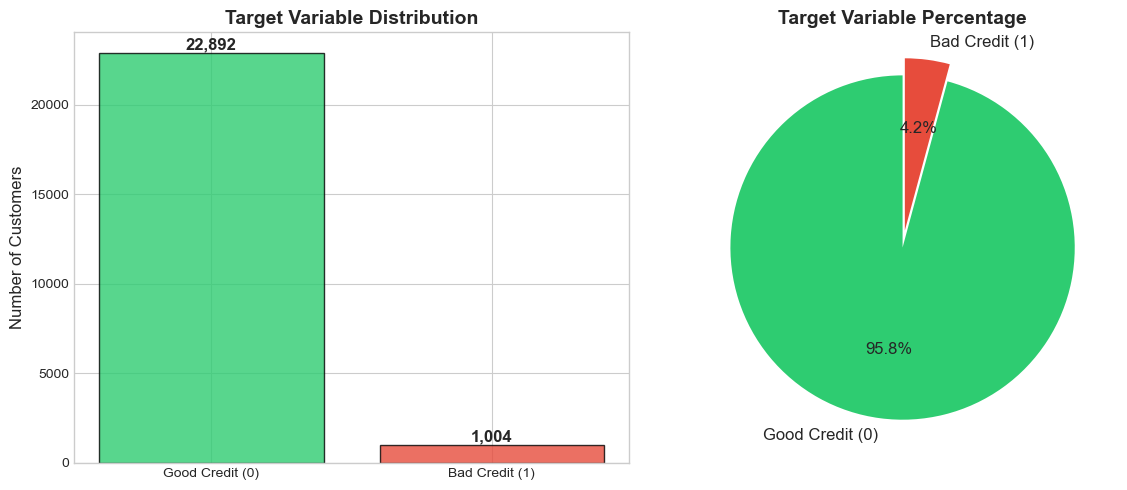


📊 Class Distribution:
   Good Credit (0): 22,892 customers (95.8%)
   Bad Credit  (1): 1,004 customers (4.2%)

   Imbalance Ratio: 22.8 : 1


In [16]:
# ============================================================
# 5.1 TARGET VARIABLE DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
target_counts = df_demographics['Bad_label'].value_counts()
colors = ['#2ecc71', '#e74c3c']
labels = ['Good Credit (0)', 'Bad Credit (1)']

axes[0].bar(labels, target_counts.values, color=colors, edgecolor='black', alpha=0.8)
axes[0].set_title('Target Variable Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Customers', fontsize=12)
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold', fontsize=12)

# Percentage pie chart
axes[1].pie(target_counts.values, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12}, explode=(0, 0.1))
axes[1].set_title('Target Variable Percentage', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print exact numbers
bad_pct = target_counts[1] / target_counts.sum() * 100
print(f"\n📊 Class Distribution:")
print(f"   Good Credit (0): {target_counts[0]:,} customers ({100 - bad_pct:.1f}%)")
print(f"   Bad Credit  (1): {target_counts[1]:,} customers ({bad_pct:.1f}%)")
print(f"\n   Imbalance Ratio: {target_counts[0] / target_counts[1]:.1f} : 1")

### 📝 Observation: Target Variable Distribution

- **Severe class imbalance**: Only ~4.2% of customers have `Bad_label = 1` (bad credit).
- The ratio is approximately **23:1** — for every 1 bad-credit customer, there are 23 good-credit customers.
- This means we **cannot rely on accuracy alone** as our evaluation metric.
- We will need to pay special attention to **Recall** (how many bad-credit customers did we correctly identify?) and **ROC-AUC** (overall discriminative ability).
- We may also need techniques like class weighting during model training.

## 5.2 Account Type Distribution

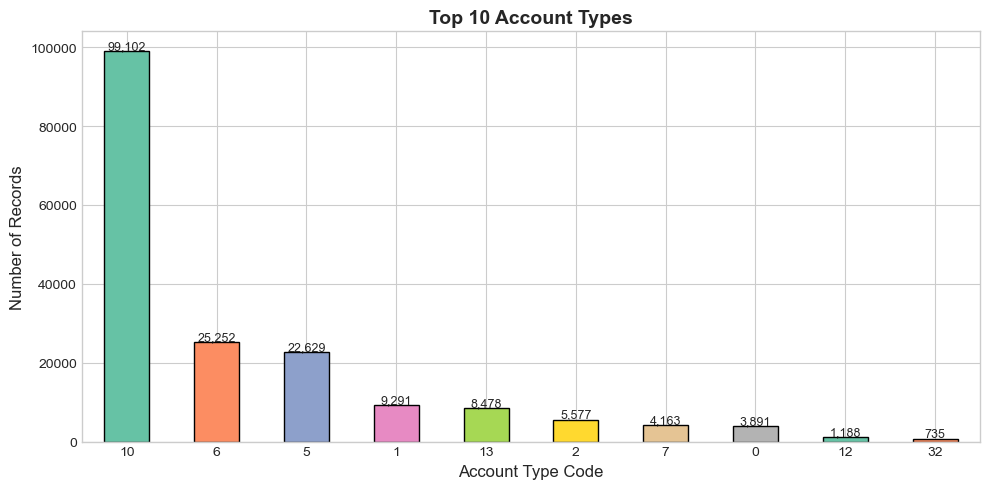


📊 Account type 10 (likely credit card) dominates the dataset.


In [17]:
# ============================================================
# 5.2 ACCOUNT TYPE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))
acct_type_counts = df_account['acct_type'].value_counts().head(10)
acct_type_counts.plot(kind='bar', ax=ax, color=sns.color_palette('Set2', 10), edgecolor='black')
ax.set_title('Top 10 Account Types', fontsize=14, fontweight='bold')
ax.set_xlabel('Account Type Code', fontsize=12)
ax.set_ylabel('Number of Records', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(acct_type_counts.values):
    ax.text(i, v + 500, f'{v:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

print("\n📊 Account type 10 (likely credit card) dominates the dataset.")

### 📝 Observation: Account Types
- **Account type 10** (likely credit card accounts) is the most common, which makes sense since this is a credit card customer dataset.
- Other account types (5, 6, 1, 13, etc.) represent different financial products the customers may have.

## 5.3 Enquiry Purpose Distribution

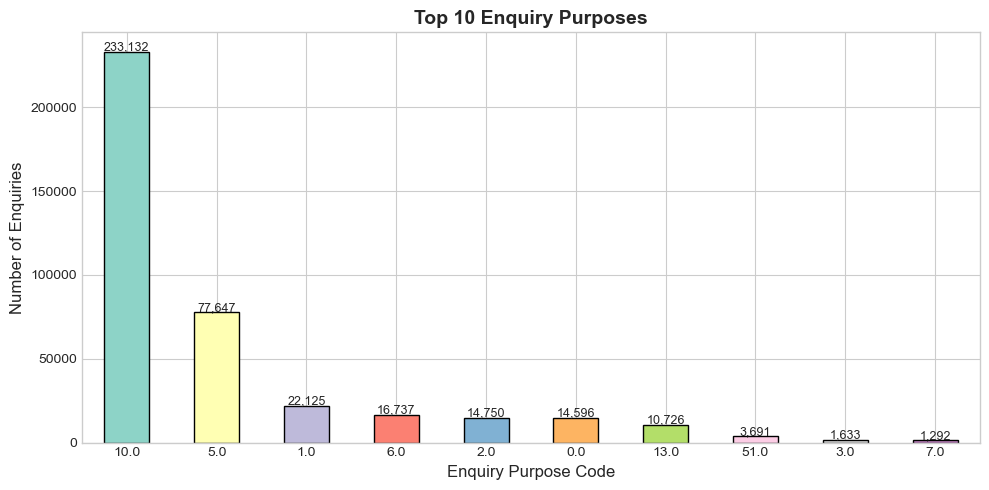

In [18]:
# ============================================================
# 5.3 ENQUIRY PURPOSE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))
enq_purpose_counts = df_enquiry['enq_purpose'].value_counts().head(10)
enq_purpose_counts.plot(kind='bar', ax=ax, color=sns.color_palette('Set3', 10), edgecolor='black')
ax.set_title('Top 10 Enquiry Purposes', fontsize=14, fontweight='bold')
ax.set_xlabel('Enquiry Purpose Code', fontsize=12)
ax.set_ylabel('Number of Enquiries', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(enq_purpose_counts.values):
    ax.text(i, v + 1000, f'{v:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### 📝 Observation: Enquiry Purposes
- Enquiry purpose **10** is the most frequent (likely credit card enquiries).
- Purpose **5** is the second most common (possibly personal loan enquiries).
- The distribution shows that most credit checks are related to a few key product types.

## 5.4 Numerical Feature Distributions (Demographics)

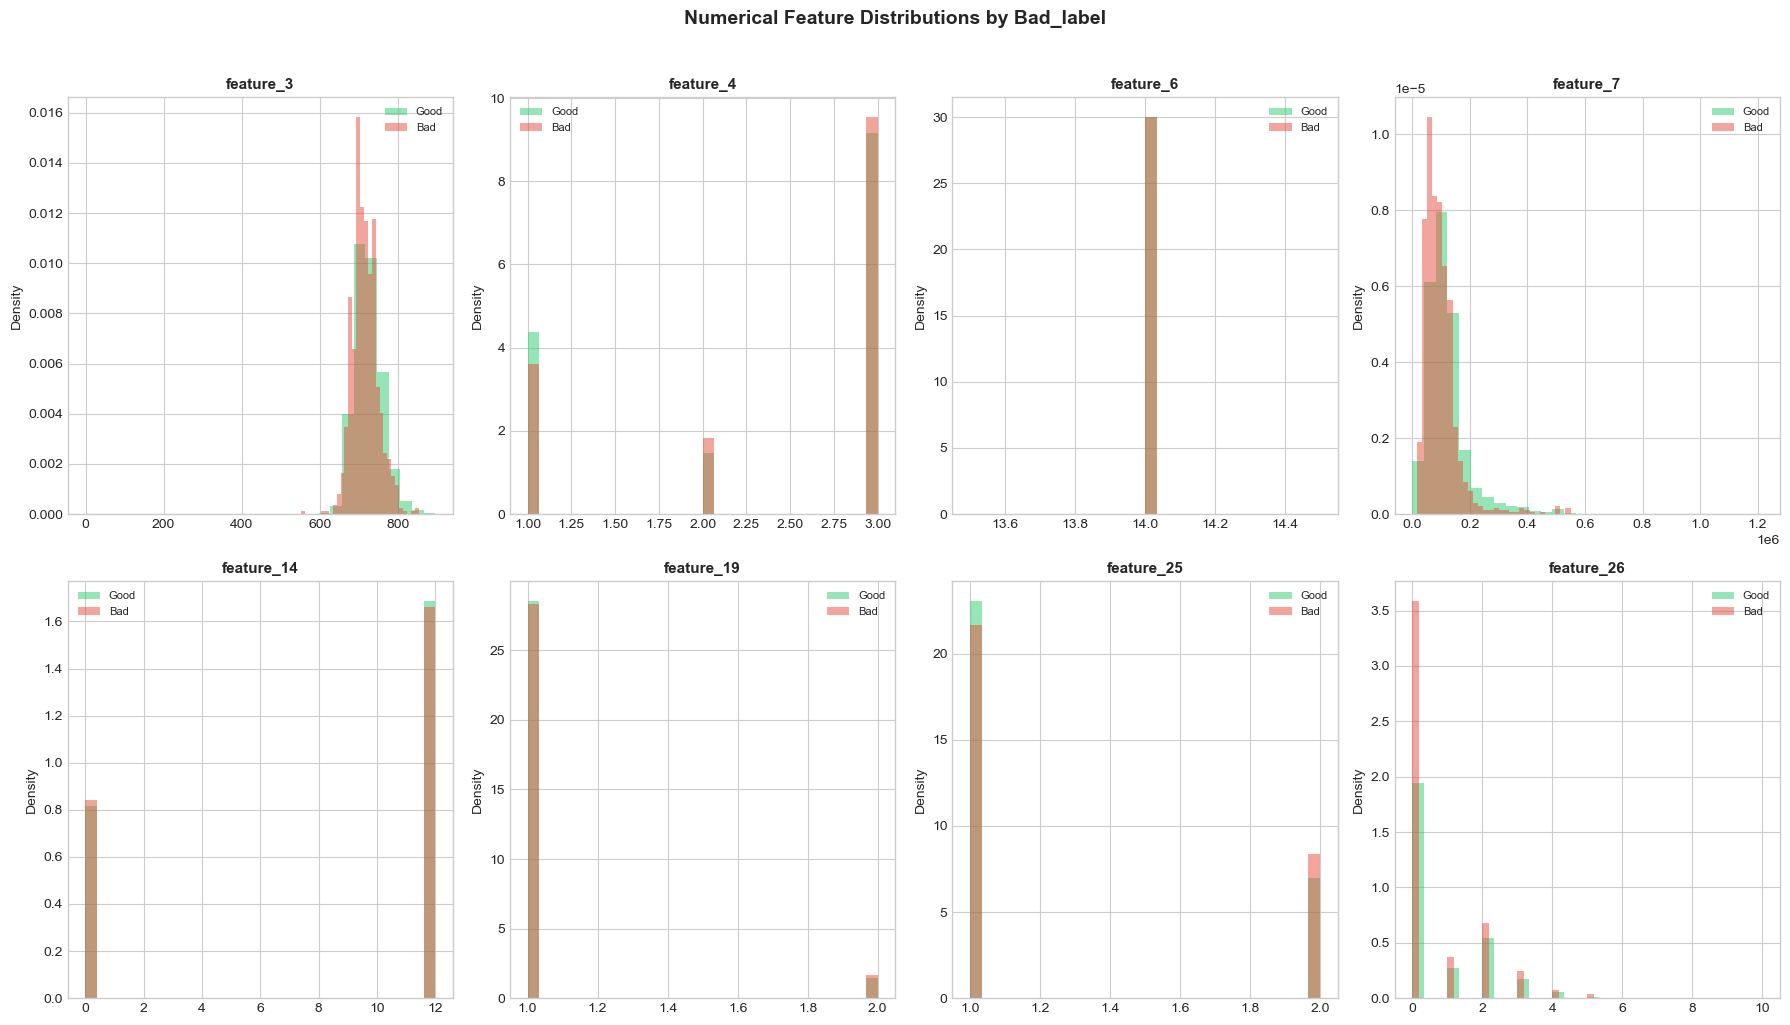

In [19]:
# ============================================================
# 5.4 KEY NUMERICAL FEATURES IN DEMOGRAPHICS
# ============================================================

# Select numeric features with reasonable non-null counts
num_features = df_demographics.select_dtypes(include=[np.number]).columns.tolist()
num_features = [c for c in num_features if c.startswith('feature_') and
                df_demographics[c].notna().sum() > len(df_demographics) * 0.3]

# Plot distributions of first 8 numeric features
plot_features = num_features[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    ax = axes[i]
    # Plot distribution split by target
    for label, color, name in [(0, '#2ecc71', 'Good'), (1, '#e74c3c', 'Bad')]:
        data = df_demographics[df_demographics['Bad_label'] == label][feat].dropna()
        ax.hist(data, bins=30, alpha=0.5, color=color, label=name, density=True)
    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylabel('Density')

plt.suptitle('Numerical Feature Distributions by Bad_label', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 📝 Observation: Numerical Features
- Some numerical features show different distributions between good and bad customers, which is promising for our model.
- `feature_3` (range ~600-900) resembles a credit score — bad customers tend to have lower values.
- Features with similar distributions for both classes may not be very useful for prediction.
- We will let the model and feature importance analysis determine which features matter most.

## 5.5 Account-Level Analysis: Balance and Credit Limit

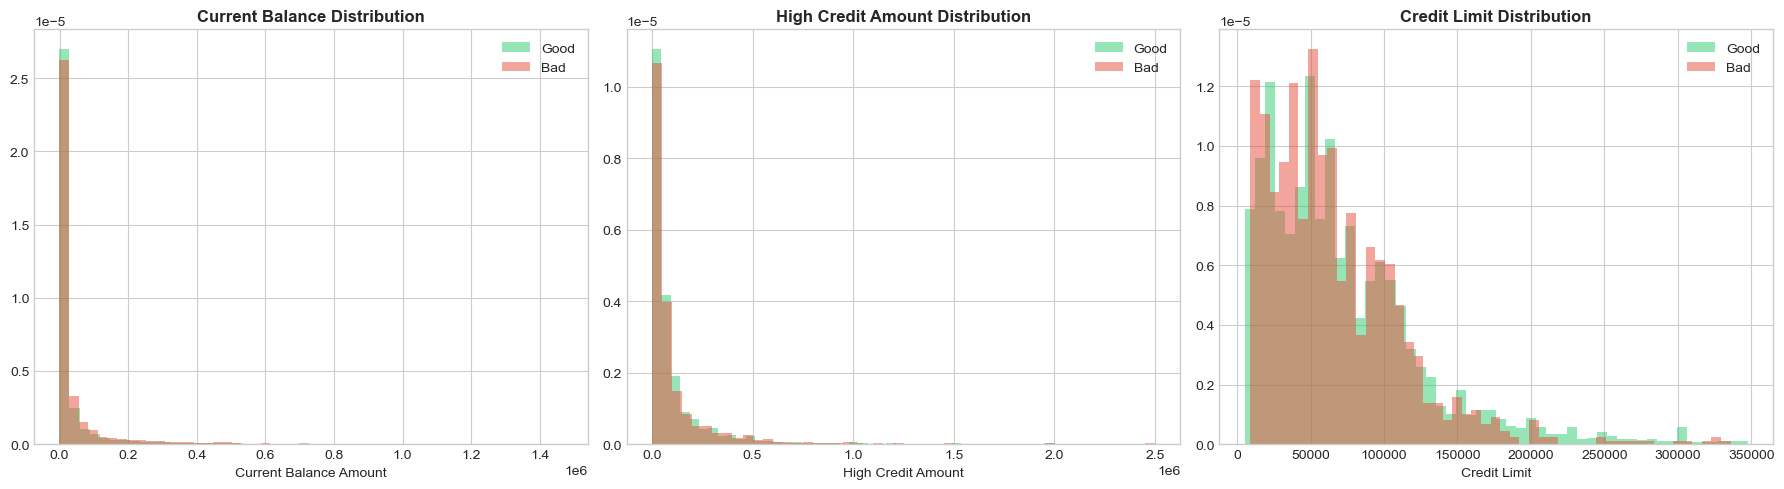

In [20]:
# ============================================================
# 5.5 ACCOUNT-LEVEL FEATURES BY TARGET
# ============================================================

# Merge account data with target for analysis
acct_with_target = df_account.merge(
    df_demographics[['customer_no', 'Bad_label']], on='customer_no', how='left'
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Current balance distribution
for label, color, name in [(0, '#2ecc71', 'Good'), (1, '#e74c3c', 'Bad')]:
    data = acct_with_target[acct_with_target['Bad_label'] == label]['cur_balance_amt']
    data = data[data.between(data.quantile(0.01), data.quantile(0.99))]
    axes[0].hist(data, bins=50, alpha=0.5, color=color, label=name, density=True)
axes[0].set_title('Current Balance Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Current Balance Amount')
axes[0].legend()

# High credit amount distribution
for label, color, name in [(0, '#2ecc71', 'Good'), (1, '#e74c3c', 'Bad')]:
    data = acct_with_target[acct_with_target['Bad_label'] == label]['high_credit_amt'].dropna()
    data = data[data.between(data.quantile(0.01), data.quantile(0.99))]
    axes[1].hist(data, bins=50, alpha=0.5, color=color, label=name, density=True)
axes[1].set_title('High Credit Amount Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('High Credit Amount')
axes[1].legend()

# Credit limit distribution
for label, color, name in [(0, '#2ecc71', 'Good'), (1, '#e74c3c', 'Bad')]:
    data = acct_with_target[acct_with_target['Bad_label'] == label]['creditlimit'].dropna()
    data = data[data.between(data.quantile(0.01), data.quantile(0.99))]
    axes[2].hist(data, bins=50, alpha=0.5, color=color, label=name, density=True)
axes[2].set_title('Credit Limit Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Credit Limit')
axes[2].legend()

plt.tight_layout()
plt.show()

# Clean up temp merge
del acct_with_target

### 📝 Observation: Account-Level Features
- Balance and credit limit distributions show some differences between good and bad customers.
- Bad-credit customers may tend to have certain patterns in their balance-to-limit ratios.
- These account-level features will be aggregated at the customer level during feature engineering.

## 5.6 Missing Value Heatmap

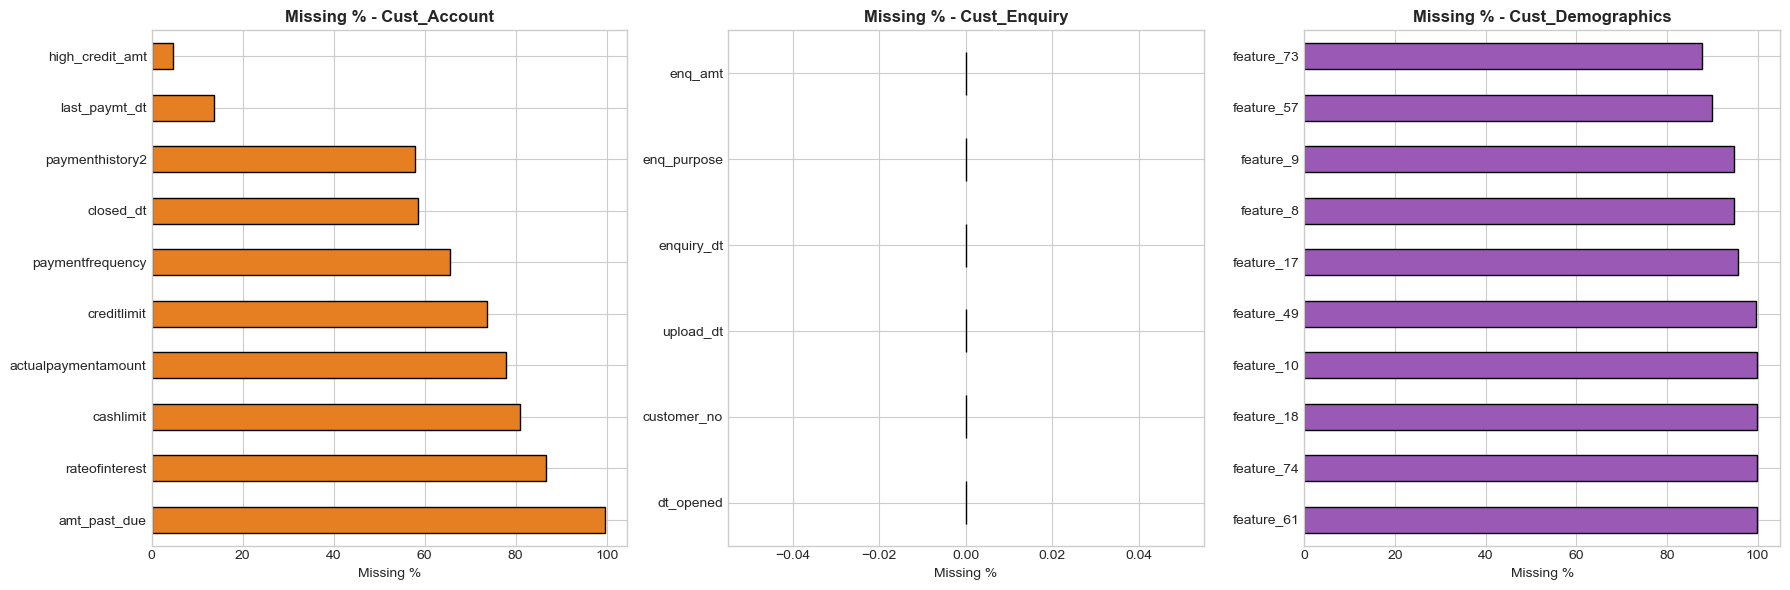

In [21]:
# ============================================================
# 5.6 MISSING VALUE VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Account missing values (top 10 columns by missingness)
acct_miss = (df_account.isnull().sum() / len(df_account) * 100).sort_values(ascending=False).head(10)
acct_miss.plot(kind='barh', ax=axes[0], color='#e67e22', edgecolor='black')
axes[0].set_title('Missing % - Cust_Account', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Missing %')

# Enquiry missing values
enq_miss = (df_enquiry.isnull().sum() / len(df_enquiry) * 100).sort_values(ascending=False)
enq_miss.plot(kind='barh', ax=axes[1], color='#3498db', edgecolor='black')
axes[1].set_title('Missing % - Cust_Enquiry', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Missing %')

# Demographics missing values (top 10)
demo_miss = (df_demographics.isnull().sum() / len(df_demographics) * 100).sort_values(ascending=False).head(10)
demo_miss.plot(kind='barh', ax=axes[2], color='#9b59b6', edgecolor='black')
axes[2].set_title('Missing % - Cust_Demographics', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Missing %')

plt.tight_layout()
plt.show()

### 📝 Observation: Missing Values
- **Cust_Account**: `amt_past_due` has ~99.5% missing values — this is because most accounts have no past-due amount. `rateofinterest`, `cashlimit`, and `actualpaymentamount` also have high missingness, varying by account type.
- **Cust_Enquiry**: Very few missing values (~0.03%), concentrated in a small set of rows.
- **Cust_Demographics**: Several anonymized features have >90% missing values. These will likely be dropped during feature selection.

> **Key Insight:** Missing `closed_dt` in accounts means the account is still **open** — this is meaningful information, not a data quality issue. Similarly, missing `amt_past_due` likely means no amount is past due (i.e., the customer is current on payments).

## 5.7 Correlation Analysis

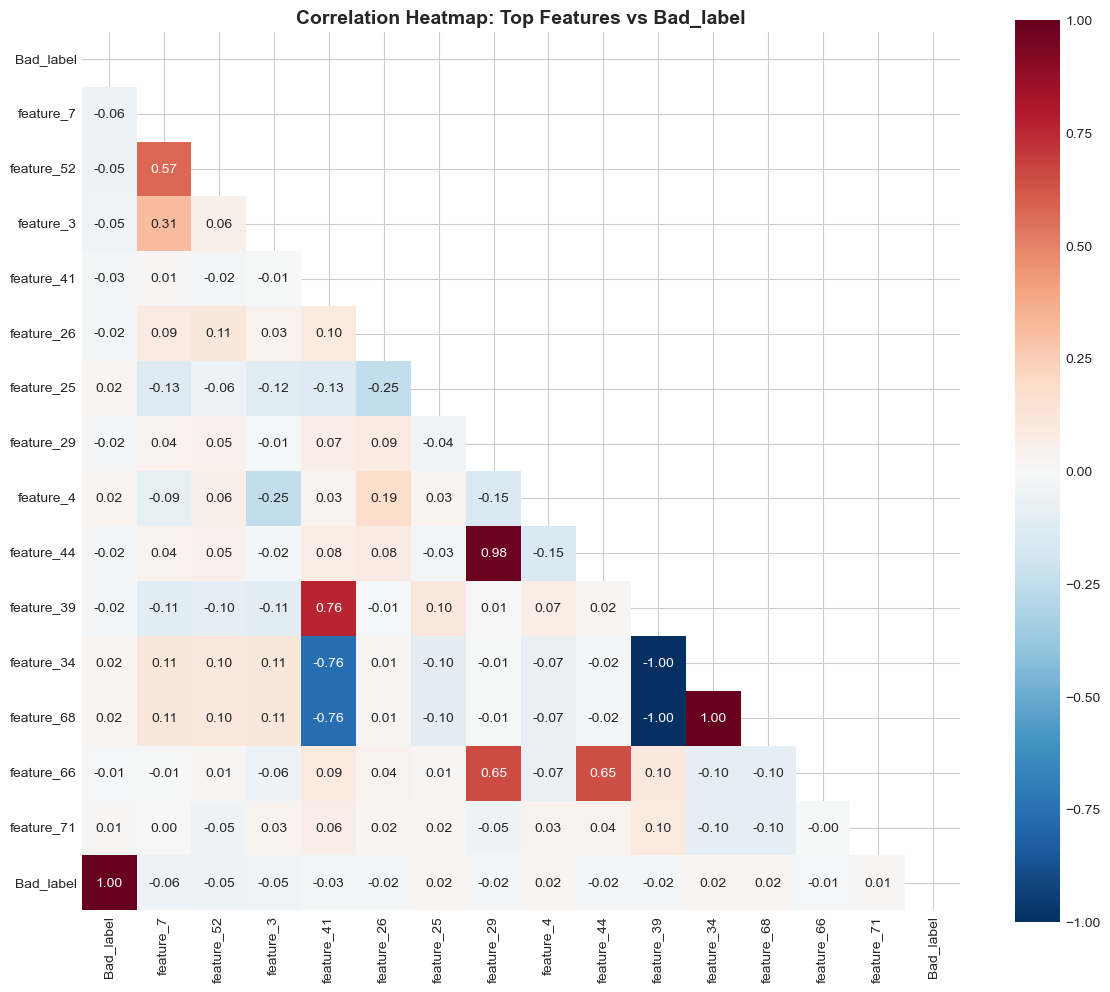


📊 Top 10 features correlated with Bad_label:
            Abs Correlation
Bad_label            1.0000
feature_7            0.0594
feature_52           0.0537
feature_3            0.0453
feature_41           0.0259
feature_26           0.0243
feature_25           0.0219
feature_29           0.0186
feature_4            0.0172
feature_44           0.0171


In [22]:
# ============================================================
# 5.7 CORRELATION HEATMAP (TOP NUMERIC FEATURES IN DEMOGRAPHICS)
# ============================================================

# Select numeric columns with >50% non-null values
num_cols = df_demographics.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if df_demographics[c].notna().sum() > len(df_demographics) * 0.5
            and c != 'customer_no']

# Calculate correlation with Bad_label
correlations = df_demographics[num_cols].corrwith(df_demographics['Bad_label']).abs().sort_values(ascending=False)
top_corr_features = correlations.head(15).index.tolist()

# Heatmap of top correlated features
fig, ax = plt.subplots(figsize=(12, 10))
corr_matrix = df_demographics[top_corr_features + ['Bad_label']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Heatmap: Top Features vs Bad_label', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print top correlations
print("\n📊 Top 10 features correlated with Bad_label:")
print(correlations.head(10).to_frame('Abs Correlation'))

### 📝 Observation: Correlation Analysis
- Some demographic features show moderate correlation with `Bad_label`.
- No single feature has a very high correlation — this is typical in credit risk, where risk depends on a combination of factors.
- Highly correlated features with each other (multicollinearity) may need attention, but tree-based models handle this well.
- We will use feature importance from models for final feature selection, not just correlation.

> **Important:** Correlation measures **linear** relationships only. Non-linear relationships (which tree-based models can capture) won't show up here.

---
# 📌 Section 6: Data Integration

**Concept: One-to-many relationships.** One customer can have many account rows (one per credit card, loan, etc.) and many enquiry rows (one per credit check). The demographics table has exactly one row per customer.

**Why does it matter?** If we joined the account table directly to demographics, a customer with 8 accounts would appear 8 times. Their target label would be copied 8 times and the model would learn from duplicated rows.

**Our approach:**
1. Summarise accounts to **one row per customer** (counts, totals, averages).
2. Summarise enquiries to **one row per customer** in the same way.
3. **Left-join** both summaries onto the demographics table. A left join keeps every demographics row, so the target label is preserved and no customer is duplicated. We check this with an `assert` statement.

### 6.1 Observation Timeline (Reference Date)

**Concept: Target leakage.** Target leakage happens when a feature contains information that would not be known at the time we make a prediction. For example, a payment that happened after the default would "leak" the answer into the features.

**Our decision:** We pick a single **reference date** (the observation point). Only account and enquiry records on or before this date are used to build features. Records after it are ignored.

In [23]:
# Some numeric columns may still be stored as text in the raw file.
# pd.to_numeric with errors='coerce' turns non-numeric entries into NaN (missing) instead of crashing.
acct_numeric_cols = ['high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'creditlimit',
                     'cashlimit', 'actualpaymentamount']
for col in acct_numeric_cols:
    if col in df_account.columns:
        df_account[col] = pd.to_numeric(df_account[col], errors='coerce')

df_enquiry['enq_amt'] = pd.to_numeric(df_enquiry['enq_amt'], errors='coerce')

print("Unique customers per dataset:")
print(f"  Cust_Account:      {df_account['customer_no'].nunique():,}")
print(f"  Cust_Enquiry:      {df_enquiry['customer_no'].nunique():,}")
print(f"  Cust_Demographics: {df_demographics['customer_no'].nunique():,}")

# Reference (observation) date
if 'reporting_dt' in df_account.columns and df_account['reporting_dt'].notna().any():
    REF_DATE = df_account['reporting_dt'].max()
else:
    REF_DATE = df_enquiry['enquiry_dt'].max()
print(f"\nReference (observation) date: {REF_DATE.date()}")

# Keep only records that were known on or before the reference date
acct_known = df_account[df_account['opened_dt'] <= REF_DATE].copy()
enq_known = df_enquiry[df_enquiry['enquiry_dt'] <= REF_DATE].copy()
print(f"\nAccount rows kept:   {len(acct_known):,} of {len(df_account):,}")
print(f"Enquiry rows kept:   {len(enq_known):,} of {len(df_enquiry):,}")

Unique customers per dataset:
  Cust_Account:      23,896
  Cust_Enquiry:      23,787
  Cust_Demographics: 23,896

Reference (observation) date: 2015-12-20

Account rows kept:   183,502 of 183,928
Enquiry rows kept:   399,249 of 399,252


### 6.2 Aggregate to Customer Level and Join

**Concept: Aggregation.** Aggregation means collapsing many rows into one summary row per customer. Examples: `sum` (total balance across all accounts), `mean` (average interest rate), `size` (number of rows = number of accounts).

**Note on missing values:** In the account table, a missing `amt_past_due` means no amount is overdue (see Section 5). So a sum over missing values is recorded as 0, which matches that meaning. Customers with no account or enquiry rows get 0 for their counts, because having zero records is a real fact about them.

In [24]:
# --- Account summary: one row per customer ---
acct_agg = acct_known.groupby('customer_no').agg(
    n_accounts=('acct_type', 'size'),
    n_open_accounts=('closed_dt', lambda s: s.isna().sum()),   # no closed date = still open
    total_high_credit=('high_credit_amt', 'sum'),
    total_cur_balance=('cur_balance_amt', 'sum'),
    total_credit_limit=('creditlimit', 'sum'),
    total_amt_past_due=('amt_past_due', 'sum'),
    mean_interest_rate=('rateofinterest', 'mean'),
).reset_index()

# --- Enquiry summary: one row per customer ---
enq_agg = enq_known.groupby('customer_no').agg(
    n_enquiries=('enq_purpose', 'size'),
    total_enquiry_amt=('enq_amt', 'sum'),
    mean_enquiry_amt=('enq_amt', 'mean'),
).reset_index()

# --- Left-join both summaries onto demographics (one row per customer) ---
df_model = (df_demographics
            .merge(acct_agg, on='customer_no', how='left')
            .merge(enq_agg, on='customer_no', how='left'))

# Safety check: the join must neither create nor lose customers
assert len(df_model) == df_demographics['customer_no'].nunique(), "Join changed the number of customers!"

print(f"Customer-level table shape: {df_model.shape}")
print(f"Customers with no account records:  {df_model['n_accounts'].isna().sum():,}")
print(f"Customers with no enquiry records:  {df_model['n_enquiries'].isna().sum():,}")

# A customer with no records truly has zero accounts / enquiries
count_cols_raw = ['n_accounts', 'n_open_accounts', 'n_enquiries']
df_model[count_cols_raw] = df_model[count_cols_raw].fillna(0)

print("\nTarget label preserved:", df_model['Bad_label'].notna().all())

Customer-level table shape: (23896, 93)
Customers with no account records:  0
Customers with no enquiry records:  109

Target label preserved: True


---
# 📌 Section 7: Feature Engineering

**What is feature engineering?** Raw tables are rarely ready for a model. Feature engineering means creating new columns that summarise customer behaviour in a useful way. For example, "how many enquiries did this customer make in the last 90 days?" is more useful to a model than a list of raw enquiry dates.



| Business-case feature | What it measures (simple words) | Status |
|---|---|---|
| `total_diff_lastpaymt_opened_dt` | Total days between opening each account and its last payment | Built |
| `mean_diff_lastpaymt_opened_dt` | Average of the same gap across accounts | Built |
| `payment_history_avg_dpd_0_29_bucket` | Average days-past-due, counting only payments that were 0 to 29 days late | Built |
| `payment_history_mean_length` | Average number of months of payment history per account | Built |
| `count_enquiry_recency_90` | Number of credit enquiries in the 90 days before the reference date | Built |
| `count_enquiry_recency_365` | Number of credit enquiries in the 365 days before the reference date | Built |
| `mean_diff_open_enquiry_dt` | Average age (in days) of the customer's enquiries | Built (interpretation to verify, see below) |
| `max_freq_enquiry` | The most enquiries a customer made for a single purpose | Built (interpretation to verify, see below) |
| `Ratio_currbalance_creditlimit` | Current balance divided by credit limit (how much of the limit is used) | Built |
| `min_months_last_30_plus` | Months since the last 30+ days-past-due event | **Skipped**: needs a confirmed month order inside the payment-history string |
| `utilisation_trend` | How credit utilisation changes over time | **Skipped**: needs several balance readings over time, but we have one per account |
| `perc_unsecured_others` | Share of accounts that are unsecured | **Skipped**: needs a mapping from account-type codes to secured/unsecured, which is not provided |



In [ ]:

def parse_dpd_codes(text):
    if pd.isna(text):
        return []
    text = str(text).strip()
    codes = []
    for i in range(0, len(text), 3):
        chunk = text[i:i + 3]
        if chunk in ('STD', '000'):
            codes.append(0)
        elif chunk.isdigit():
            codes.append(int(chunk))
    return codes

# Check the parser on real values before trusting it
for s in df_account['paymenthistory1'].dropna().head(3):
    print(f"Raw (first 30 chars): {s[:30]}  ->  parsed codes: {parse_dpd_codes(s)[:8]}")

Raw (first 30 chars): STDSTDSTDXXXXXXXXXXXXXXXSTDXXX  ->  parsed codes: [0, 0, 0, 0, 0]
Raw (first 30 chars): 000000000000000000000000000000  ->  parsed codes: [0, 0, 0, 0, 0, 0, 0, 0]
Raw (first 30 chars): 000000000000000000000000000000  ->  parsed codes: [0, 0, 0, 0, 0, 0, 0, 0]


**What to check in the output above:** The parsed codes should look like plausible days-past-due values (mostly 0, sometimes 30, 60, 90). If they look wrong, the payment-history strings use a different layout, and the parser must be adjusted before the payment-history features are used.

In [26]:
acct_rows = acct_known.copy()

# Days from account opening to last payment (NaN if either date is missing)
acct_rows['days_open_to_lastpay'] = (acct_rows['last_paymt_dt'] - acct_rows['opened_dt']).dt.days

# Payment-history statistics for each account
acct_rows['pay_codes'] = acct_rows['paymenthistory1'].apply(parse_dpd_codes)
acct_rows['pay_months_observed'] = acct_rows['pay_codes'].apply(len)
acct_rows['avg_dpd_0_29'] = acct_rows['pay_codes'].apply(
    lambda codes: np.mean([c for c in codes if c < 30]) if any(c < 30 for c in codes) else np.nan)

# --- Account-based features (per customer) ---
acct_features = acct_rows.groupby('customer_no').agg(
    total_diff_lastpaymt_opened_dt=('days_open_to_lastpay', 'sum'),
    mean_diff_lastpaymt_opened_dt=('days_open_to_lastpay', 'mean'),
    payment_history_avg_dpd_0_29_bucket=('avg_dpd_0_29', 'mean'),
    payment_history_mean_length=('pay_months_observed', 'mean'),
).reset_index()

# --- Ratio: current balance / credit limit ---
# Division by zero is avoided by treating a zero limit as missing (NaN)
ratio_base = acct_agg[['customer_no', 'total_cur_balance', 'total_credit_limit']].copy()
ratio_base['Ratio_currbalance_creditlimit'] = (
    ratio_base['total_cur_balance'] / ratio_base['total_credit_limit'].replace(0, np.nan))
ratio_features = ratio_base[['customer_no', 'Ratio_currbalance_creditlimit']]

# --- Enquiry-based features (per customer) ---
enq_rows = enq_known.copy()
# Days between each enquiry and the reference date (0 = on the reference date)
enq_rows['days_before_ref'] = (REF_DATE - enq_rows['enquiry_dt']).dt.days

def count_within(days):
    recent = enq_rows[enq_rows['days_before_ref'] <= days]
    return recent.groupby('customer_no').size().rename(f'count_enquiry_recency_{days}')

enq_features = pd.concat([
    count_within(90),
    count_within(365),
    enq_rows.groupby('customer_no')['days_before_ref'].mean().rename('mean_diff_open_enquiry_dt'),
    enq_rows.groupby(['customer_no', 'enq_purpose']).size()
            .groupby('customer_no').max().rename('max_freq_enquiry'),
], axis=1).reset_index()

# --- Join every new feature onto the customer-level table ---
df_model = (df_model
            .merge(acct_features, on='customer_no', how='left')
            .merge(ratio_features, on='customer_no', how='left')
            .merge(enq_features, on='customer_no', how='left'))

# Customers with no enquiries in a window have a count of 0, not a missing value
zero_fill_cols = ['count_enquiry_recency_90', 'count_enquiry_recency_365', 'max_freq_enquiry']
df_model[zero_fill_cols] = df_model[zero_fill_cols].fillna(0)

ENGINEERED_FEATURES = [
    'total_diff_lastpaymt_opened_dt', 'mean_diff_lastpaymt_opened_dt',
    'payment_history_avg_dpd_0_29_bucket', 'payment_history_mean_length',
    'Ratio_currbalance_creditlimit',
    'count_enquiry_recency_90', 'count_enquiry_recency_365',
    'mean_diff_open_enquiry_dt', 'max_freq_enquiry',
]

print("Engineered features built (share of customers with a value):")
coverage = (df_model[ENGINEERED_FEATURES].notna().mean() * 100).round(1)
print(coverage.to_string())

print("\nFeatures skipped (cannot be calculated from the provided data):")
skipped_features = {
    'min_months_last_30_plus': 'Needs the month order inside the payment-history string, which is not confirmed.',
    'utilisation_trend': 'Needs several balance readings over time; the data has one balance per account.',
    'perc_unsecured_others': 'Needs a mapping from account-type codes to secured/unsecured, which is not provided.',
}
for feat, reason in skipped_features.items():
    print(f"  - {feat}: {reason}")

Engineered features built (share of customers with a value):
total_diff_lastpaymt_opened_dt        100.0000
mean_diff_lastpaymt_opened_dt          99.8000
payment_history_avg_dpd_0_29_bucket   100.0000
payment_history_mean_length           100.0000
Ratio_currbalance_creditlimit          83.1000
count_enquiry_recency_90              100.0000
count_enquiry_recency_365             100.0000
mean_diff_open_enquiry_dt              99.5000
max_freq_enquiry                      100.0000

Features skipped (cannot be calculated from the provided data):
  - min_months_last_30_plus: Needs the month order inside the payment-history string, which is not confirmed.
  - utilisation_trend: Needs several balance readings over time; the data has one balance per account.
  - perc_unsecured_others: Needs a mapping from account-type codes to secured/unsecured, which is not provided.


**Explanation of the features in simple language:**

- **Days-based features** (`total_` and `mean_diff_lastpaymt_opened_dt`): how long, on average, customers have kept their accounts active. Very short gaps may mean something different from long ones, so the model is free to learn that.
- **`payment_history_avg_dpd_0_29_bucket`**: summarises small delays. A customer who is often a few days late behaves differently from one who always pays on time.
- **`payment_history_mean_length`**: how much payment history we can see for each customer.
- **`Ratio_currbalance_creditlimit`**: how much of the available credit is being used. Customers close to their limit may be under more financial pressure.
- **`count_enquiry_recency_90` / `_365`**: many recent credit checks can signal that a customer is looking for new credit, which is sometimes linked to financial stress.
- **`mean_diff_open_enquiry_dt`**: how old the customer's enquiries are on average.
- **`max_freq_enquiry`**: the largest number of enquiries made for one purpose. Repeated applications for the same purpose can be a warning sign.

> **Reminder:** These features show association with bad credit. They do not prove that any feature causes default.

---
# 📌 Section 8: Feature Selection

**What is feature selection?** Not every column helps the model. Some are mostly missing, some never change, and some add noise. Feature selection keeps the columns that are most useful for predicting `Bad_label`.

**Concept: Mutual information.** This measures how much knowing a feature's value reduces our uncertainty about `Bad_label`. A score of 0 means the feature tells us nothing about the target.

**Concept: Gain importance.** A tree-based model (LightGBM) uses each feature to split customers into groups. "Gain" is the improvement in prediction quality each feature brings. Higher gain means the model relied on that feature more.

**Target leakage protection:** To avoid letting the test customers influence feature selection, we split the data into a training part and a test part **first**, and we run all selection steps on the training part only. The test part is held back until Section 12.

**Why not just use correlation?** Correlation only measures straight-line relationships. Mutual information and tree-based gain can also capture curved and interaction effects, which matter in credit risk.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from lightgbm import LGBMClassifier

MISSING_THRESHOLD = 0.80   # drop features with more than 80% missing values in the training data

candidate_cols = df_model.select_dtypes(include=[np.number]).columns.difference(['customer_no', 'Bad_label'])
candidate_cols = [c for c in candidate_cols if c not in high_miss_cols]

# Remove features that are mostly missing or have only one value (no information)
X_all = df_model[candidate_cols]
y_all = df_model['Bad_label']
missing_share = X_all.isnull().mean()
candidate_cols = [c for c in candidate_cols
                  if missing_share[c] <= MISSING_THRESHOLD and X_all[c].nunique() > 1]
print(f"Candidate features after basic filters: {len(candidate_cols)}")

# Stratified split: keeps the same bad-customer percentage in both parts
X = df_model[candidate_cols]
y = df_model['Bad_label']
X_train_fs, X_test, y_train_fs, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

print(f"\nTraining part: {X_train_fs.shape[0]:,} customers | bad rate: {y_train_fs.mean():.2%}")
print(f"Test part:     {X_test.shape[0]:,} customers | bad rate: {y_test.mean():.2%}")

Candidate features after basic filters: 48

Training part: 16,727 customers | bad rate: 4.20%
Test part:     7,169 customers | bad rate: 4.20%


In [ ]:
# Fill missing values with the median of the TRAINING data only
imputer_fs = SimpleImputer(strategy='median')
X_train_imp = imputer_fs.fit_transform(X_train_fs)

# 1) Mutual information with the target
mi_scores = mutual_info_classif(X_train_imp, y_train_fs, random_state=42)

# 2) LightGBM gain importance
#    class_weight='balanced' gives bad-credit customers more weight, because they are rare
lgbm_fs = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight='balanced',
                         random_state=42, verbose=-1)
lgbm_fs.fit(X_train_imp, y_train_fs)
gain = lgbm_fs.booster_.feature_importance(importance_type='gain')

importance_table = pd.DataFrame({
    'feature': candidate_cols,
    'mutual_info': mi_scores,
    'lgbm_gain': gain,
})
importance_table['gain_share_%'] = 100 * importance_table['lgbm_gain'] / importance_table['lgbm_gain'].sum()

# Direction: is the feature typically higher or lower for bad-credit customers?
medians = X_train_fs.assign(Bad_label=y_train_fs.values).groupby('Bad_label').median().T
importance_table['median_good'] = importance_table['feature'].map(medians[0])
importance_table['median_bad'] = importance_table['feature'].map(medians[1])
importance_table['interpretation'] = np.select(
    [importance_table['median_good'].isna() | importance_table['median_bad'].isna(),
     importance_table['median_bad'] > importance_table['median_good'],
     importance_table['median_bad'] < importance_table['median_good']],
    ['Not comparable (missing values)',
     'Higher typical value for bad-credit customers',
     'Lower typical value for bad-credit customers'],
    default='Same typical value')

importance_table = (importance_table
                    .sort_values('lgbm_gain', ascending=False)
                    .reset_index(drop=True))

print("Top 20 features:")
importance_table.head(20)[['feature', 'mutual_info', 'gain_share_%', 'interpretation']]

  File "c:\Users\Admin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Admin\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\anaconda3\Lib\subprocess.

Top 20 features:


,feature,mutual_info,gain_share_%,interpretation
0,feature_7,0.0021,5.9692,Lower typical value for bad-credit customers
1,feature_3,0.0051,5.3133,Lower typical value for bad-credit customers
2,mean_diff_open_enquiry_dt,0.0033,4.7273,Lower typical value for bad-credit customers
3,payment_history_mean_length,0.0039,4.6907,Lower typical value for bad-credit customers
4,mean_diff_lastpaymt_opened_dt,0.0011,4.5948,Lower typical value for bad-credit customers
5,total_credit_limit,0.0012,4.5915,Lower typical value for bad-credit customers
6,Ratio_currbalance_creditlimit,0.0014,4.2963,Higher typical value for bad-credit customers
7,mean_enquiry_amt,0.0029,4.1397,Higher typical value for bad-credit customers
8,total_diff_lastpaymt_opened_dt,0.0000,4.0457,Lower typical value for bad-credit customers
9,total_high_credit,0.0032,3.6730,Lower typical value for bad-credit customers


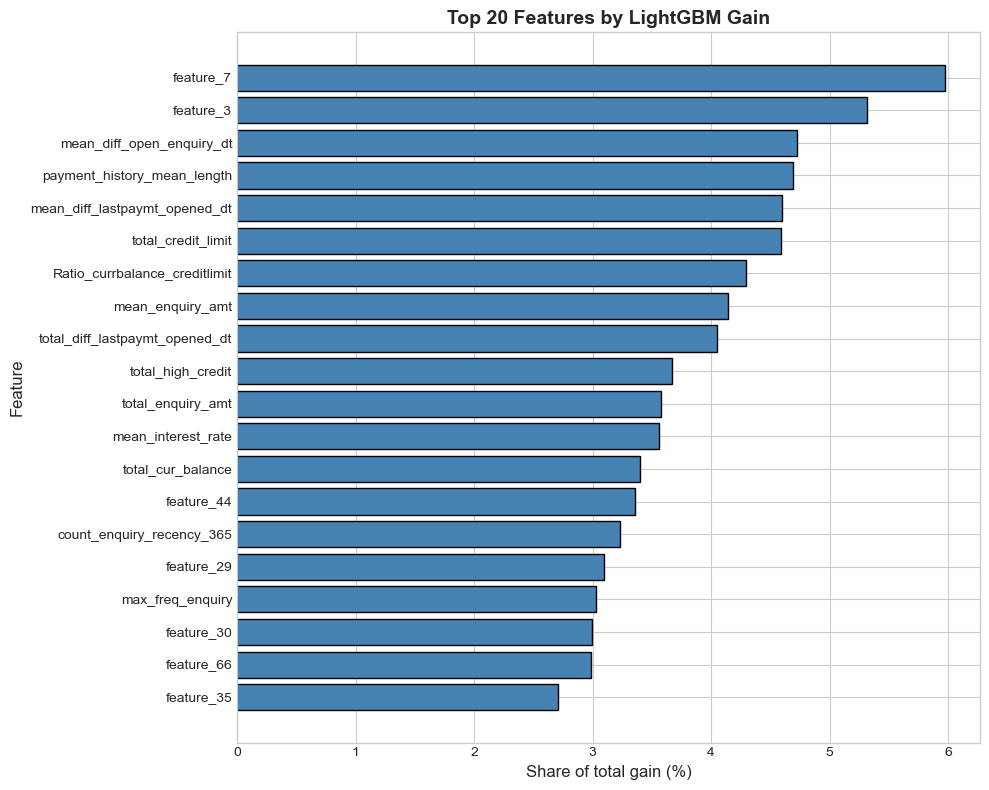

In [29]:
top20 = importance_table.head(20).iloc[::-1]   # reverse so the largest bar is at the top

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top20['feature'], top20['gain_share_%'], color='steelblue', edgecolor='black')
ax.set_title('Top 20 Features by LightGBM Gain', fontsize=14, fontweight='bold')
ax.set_xlabel('Share of total gain (%)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 📝 How to read the feature importance table

- **`mutual_info`** and **`gain_share_%`** both rank features by usefulness. A feature that scores high on both is a strong candidate.
- **`interpretation`** only describes the typical direction in the training data (for example, "higher typical value for bad-credit customers"). It is an association, not a cause.
- Features with very low scores add little. We keep the top features for the model in the next step.

**Decision:** We keep the top 40 features by LightGBM gain. The number 40 is a practical choice: it keeps the most useful signals and removes the long tail of weak features. Keeping too many weak features can make the model noisier.

In [30]:
TOP_K = 40
SELECTED_FEATURES = importance_table['feature'].head(TOP_K).tolist()
print(f"Selected {len(SELECTED_FEATURES)} features for modelling.")

Selected 40 features for modelling.


---
# 📌 Section 9: Prepare Data for Machine Learning

**Concept: Train-test split.** We train the model on one part of the data (training set) and check it on data it has never seen (test set). Testing on training data would give over-optimistic results.

**Concept: Stratification.** Because bad-credit customers are rare, a random split could put very few of them in the test set. Stratified splitting keeps the bad-customer percentage the same in both parts (we already did this in Section 8).

**Concept: Missing values.** Median imputation replaces each missing value with the median of that feature in the training data. Median is used because it is not pulled around by extreme values.

**Concept: Scaling.** Logistic Regression is sensitive to the size of numbers, so we standardise its inputs (mean 0, spread 1). Tree-based models do not need scaling.

**Avoiding data leakage:** Imputation and scaling are placed **inside** a `Pipeline`. Inside cross-validation, the pipeline learns the median and the scale only from the training folds, then applies them to the validation fold. The test set is only transformed, never used to learn anything.

**Time-based split:** We considered a time-based split. The data does not give us a clean, reliable observation date for each customer, so we use a stratified random split. A time-based split is listed under future improvements.

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_train = X_train_fs[SELECTED_FEATURES]
y_train = y_train_fs
X_test_sel = X_test[SELECTED_FEATURES]

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count   # used by XGBoost to handle imbalance

print(f"Training features: {X_train.shape}")
print(f"Test features:     {X_test_sel.shape}")
print(f"Training bad rate: {y_train.mean():.2%} | Test bad rate: {y_test.mean():.2%}")
print(f"Good : Bad ratio in training data: {neg_count / pos_count:.1f} : 1")

def make_pipeline(model, scale=False):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

Training features: (16727, 40)
Test features:     (7169, 40)
Training bad rate: 4.20% | Test bad rate: 4.20%
Good : Bad ratio in training data: 22.8 : 1


---
# 📌 Section 10: Model Building

We compare five classification models, from simplest to most complex.

| Model | How it works (simple words) | Advantages | Limitations |
|---|---|---|---|
| **Logistic Regression** (baseline) | Adds up weighted feature values and converts the total into a probability | Simple, fast, easy to explain to a bank | Only captures straight-line patterns |
| **Decision Tree** | Asks a series of yes/no questions (e.g., "is the ratio above 0.8?") | Easy to visualise and explain | Tends to memorise training data (overfits) |
| **Random Forest** | Builds many decision trees on random samples and averages them | More stable than one tree; handles curved patterns | Slower; harder to explain |
| **XGBoost** | Builds trees one after another, each fixing the previous errors | Often very accurate on tabular data | Many settings to tune |
| **LightGBM** | Like XGBoost but faster on large data | Fast; strong accuracy | Can overfit if not tuned |

**Handling class imbalance:** Bad-credit customers are rare, so each model is told to give them more weight (`class_weight='balanced'` or `scale_pos_weight`). This is justified because missing a risky customer is more costly than a false alarm.

**Concept: Cross-validation.** We split the training data into 5 folds. The model is trained on 4 folds and tested on the 5th, rotating through all folds. The average score is more reliable than a single split. We use **ROC-AUC** as the score because it does not depend on a single probability cut-off and works well for imbalanced data.

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

models = {
    'Logistic Regression': make_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced'), scale=True),
    'Decision Tree': make_pipeline(
        DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=42)),
    'Random Forest': make_pipeline(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced',
                               n_jobs=-1, random_state=42)),
    'XGBoost': make_pipeline(
        XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                      scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42)),
    'LightGBM': make_pipeline(
        LGBMClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                       class_weight='balanced', random_state=42, verbose=-1)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV ROC-AUC (mean)': scores.mean(), 'CV ROC-AUC (std)': scores.std()})

cv_table = pd.DataFrame(cv_rows).sort_values('CV ROC-AUC (mean)', ascending=False).reset_index(drop=True)
print("Cross-validation results on the TRAINING data (5 folds):")
cv_table

Cross-validation results on the TRAINING data (5 folds):


,Model,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Random Forest,0.6594,0.0226
1,Logistic Regression,0.6569,0.0146
2,LightGBM,0.6362,0.0098
3,XGBoost,0.6346,0.0108
4,Decision Tree,0.6010,0.0085


### 📝 Reading the cross-validation table

- A higher mean ROC-AUC means the model separates good and bad customers better on average.
- A small standard deviation means the result is stable across folds. A large one means the result depends heavily on which customers landed in which fold.
- These scores come only from the training data. The test set has not been used yet.

---
# 📌 Section 11: Hyperparameter Tuning

**What is a hyperparameter?** A setting we choose before training, such as how many trees to build or how fast the model learns. It is not learned from the data.

**What is tuning?** Trying different combinations of settings and keeping the one that performs best in cross-validation.

**Why RandomizedSearchCV?** Trying every combination would take too long. `RandomizedSearchCV` tests a random sample of 20 combinations, which is a practical trade-off between quality and time.

**Parameters tuned (LightGBM, the model with the most promising results in Section 10):**

| Parameter | What it controls (simple words) |
|---|---|
| `n_estimators` | How many trees to build |
| `learning_rate` | How big a step each tree takes (smaller = slower but often more accurate) |
| `num_leaves` | How complex each tree can become |
| `min_child_samples` | Minimum customers needed before a tree can split (higher = less overfitting) |
| `subsample` | Share of customers each tree sees (adds randomness that reduces overfitting) |
| `colsample_bytree` | Share of features each tree sees |
| `reg_lambda` | Penalty that discourages overly large adjustments |

**Scoring metric:** ROC-AUC, the same as Section 10, so results are comparable.

**Cross-validation for tuning:** 3 folds, to keep computation time reasonable.

In [33]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'model__n_estimators': [200, 400, 600],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__num_leaves': [15, 31, 63],
    'model__min_child_samples': [20, 50, 100],
    'model__subsample': [0.7, 0.9],
    'model__colsample_bytree': [0.7, 0.9],
    'model__reg_lambda': [0, 1, 5],
}

search = RandomizedSearchCV(
    estimator=models['LightGBM'],
    param_distributions=param_distributions,
    n_iter=20,
    scoring='roc_auc',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best parameters found:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__', ''):<20} {v}")
print(f"\nBest tuning CV ROC-AUC: {search.best_score_:.4f}")

Best parameters found:
  subsample            0.7
  reg_lambda           5
  num_leaves           15
  n_estimators         400
  min_child_samples    50
  learning_rate        0.01
  colsample_bytree     0.7

Best tuning CV ROC-AUC: 0.6590


**Decision rule:** We only keep the tuned LightGBM if it beats the untuned models on cross-validation. The choice is made on training-data scores, not on the test set.

---
# 📌 Section 12: Model Evaluation

Now we check every model on the **test set** (customers the models have never seen).

**Why accuracy alone is not enough:** If 96% of customers are good, a model that says "good" for everyone gets 96% accuracy and is useless. For credit risk we care most about **recall** for bad customers, because a missed risky customer costs the bank more than a wrongly flagged good one.

**The metrics:**

| Metric | Simple meaning |
|---|---|
| **Accuracy** | Share of all predictions that were correct |
| **Precision** | Of the customers flagged as risky, how many really were bad |
| **Recall** | Of all truly bad customers, how many did we catch |
| **F1-score** | A balance between precision and recall |
| **ROC-AUC** | How well the model ranks bad customers above good ones, regardless of cut-off (1.0 = perfect, 0.5 = random) |
| **Gini** | A credit-risk scale derived from AUC: **Gini = (2 × ROC-AUC − 1) × 100** |

**Gini explained:** Gini measures how well the model separates good and bad customers. An AUC of 0.5 gives a Gini of 0 (random guessing). A perfect model gives 100. We express it as a percentage so it can be compared with the business-case benchmark of **37.9**.

**Confusion matrix:** A table showing correct and incorrect predictions. It shows exactly how many bad customers were missed (false negatives).

**Classification threshold:** Classification metrics use a probability cut-off of 0.5 (predict "bad" if probability ≥ 0.5). ROC-AUC and Gini do not depend on this cut-off.

In [34]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

BENCHMARK_GINI = 37.9   # from the business case
CUTOFF = 0.5            # probability threshold for class predictions

# Fit every model on the full training set
fitted_models = {}
for name, pipe in models.items():
    fitted_models[name] = pipe.fit(X_train, y_train)
fitted_models['LightGBM (tuned)'] = search.best_estimator_

def evaluate(name, model):
    proba = model.predict_proba(X_test_sel)[:, 1]
    pred = (proba >= CUTOFF).astype(int)
    auc = roc_auc_score(y_test, proba)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (bad)': precision_score(y_test, pred, zero_division=0),
        'Recall (bad)': recall_score(y_test, pred, zero_division=0),
        'F1 (bad)': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': auc,
        'Gini (%)': (2 * auc - 1) * 100,
    }, proba

results = []
probas = {}
for name, model in fitted_models.items():
    row, proba = evaluate(name, model)
    results.append(row)
    probas[name] = proba

results_table = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print("Test-set results for all models (for transparency; model choice was made in Section 11):")
results_table.style.format({c: '{:.4f}' for c in results_table.columns if c not in ['Model', 'Gini (%)']}
                           | {'Gini (%)': '{:.2f}'})

Test-set results for all models (for transparency; model choice was made in Section 11):


,Model,Accuracy,Precision (bad),Recall (bad),F1 (bad),ROC-AUC,Gini (%)
0,Logistic Regression,0.6151,0.0685,0.6478,0.1238,0.6812,36.25
1,LightGBM (tuned),0.7312,0.0792,0.5083,0.1370,0.6760,35.20
2,Random Forest,0.9499,0.1081,0.0266,0.0427,0.6717,34.34
3,LightGBM,0.9212,0.0875,0.0930,0.0902,0.6502,30.03
4,XGBoost,0.7922,0.0787,0.3688,0.1297,0.6472,29.43
5,Decision Tree,0.5359,0.0540,0.6080,0.0991,0.5748,14.95


Final model (chosen by training cross-validation): Random Forest
Its cross-validation ROC-AUC: 0.6594

Classification report on the TEST set:
              precision    recall  f1-score   support

    Good (0)       0.96      0.99      0.97      6868
     Bad (1)       0.11      0.03      0.04       301

    accuracy                           0.95      7169
   macro avg       0.53      0.51      0.51      7169
weighted avg       0.92      0.95      0.94      7169



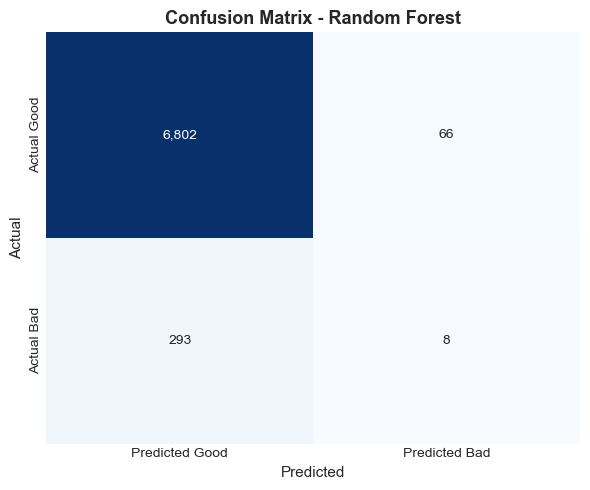

Bad customers missed (false negatives): 293 of 301 actual bad customers
Good customers flagged (false positives): 66 of 6,868 actual good customers


In [35]:
# Final model: the candidate with the highest CROSS-VALIDATION ROC-AUC on the training data
candidate_cv_scores = {'LightGBM (tuned)': search.best_score_}
for _, row in cv_table.iterrows():
    candidate_cv_scores[row['Model']] = row['CV ROC-AUC (mean)']

final_name = max(candidate_cv_scores, key=candidate_cv_scores.get)
final_model = fitted_models[final_name]
final_proba = probas[final_name]
final_pred = (final_proba >= CUTOFF).astype(int)

print(f"Final model (chosen by training cross-validation): {final_name}")
print(f"Its cross-validation ROC-AUC: {candidate_cv_scores[final_name]:.4f}\n")

print("Classification report on the TEST set:")
print(classification_report(y_test, final_pred, target_names=['Good (0)', 'Bad (1)'], zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, final_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Predicted Good', 'Predicted Bad'],
            yticklabels=['Actual Good', 'Actual Bad'])
ax.set_title(f'Confusion Matrix - {final_name}', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('Actual', fontsize=11)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Bad customers missed (false negatives): {fn:,} of {fn + tp:,} actual bad customers")
print(f"Good customers flagged (false positives): {fp:,} of {tn + fp:,} actual good customers")

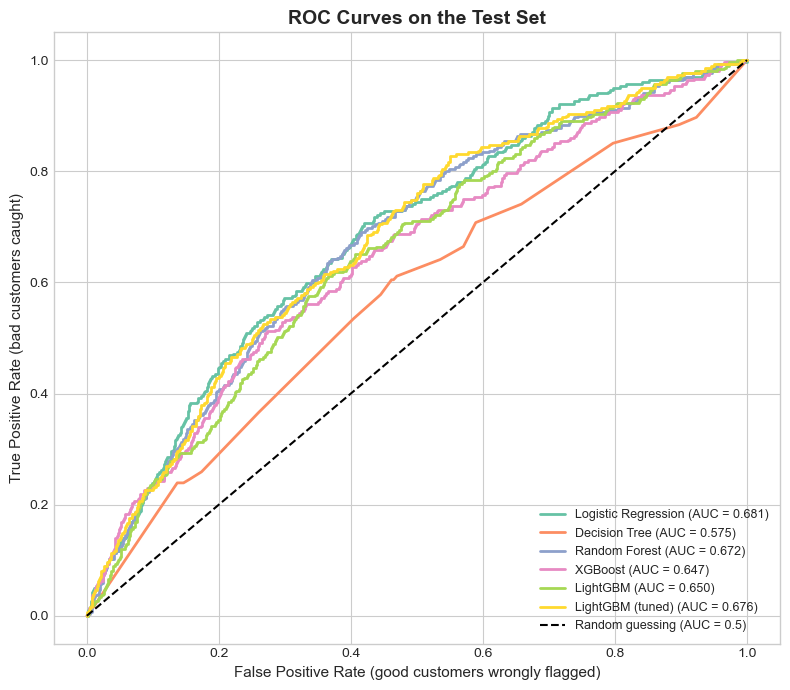

In [36]:
# ROC curves for all models on the test set
fig, ax = plt.subplots(figsize=(8, 7))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc_val:.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
ax.set_title('ROC Curves on the Test Set', fontsize=14, fontweight='bold')
ax.set_xlabel('False Positive Rate (good customers wrongly flagged)', fontsize=11)
ax.set_ylabel('True Positive Rate (bad customers caught)', fontsize=11)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [37]:
# Compare the final model's test Gini with the business-case benchmark
final_row = results_table[results_table['Model'] == final_name].iloc[0]
final_gini = final_row['Gini (%)']
gap = final_gini - BENCHMARK_GINI

print(f"Final model: {final_name}")
print(f"Test-set Gini:       {final_gini:.2f}")
print(f"Benchmark Gini:      {BENCHMARK_GINI:.2f}")
print(f"Difference:          {gap:+.2f} points\n")

if gap >= 0:
    print("RESULT: The final model's test Gini is at or above the benchmark.")
else:
    print("RESULT: The final model's test Gini is below the benchmark.")
print("Note: the benchmark may have been measured on a different customer population,")
print("so this comparison is indicative, not a like-for-like test.")

Final model: Random Forest
Test-set Gini:       34.34
Benchmark Gini:      37.90
Difference:          -3.56 points

RESULT: The final model's test Gini is below the benchmark.
Note: the benchmark may have been measured on a different customer population,
so this comparison is indicative, not a like-for-like test.


### 📝 How to read the evaluation results

- Compare **Recall (bad)** across models. A model that catches more bad customers is more useful to the bank, provided its precision is still acceptable.
- Compare **Gini** with the benchmark of 37.9. We report the number exactly as the code computes it, whichever way the comparison comes out.
- The **confusion matrix** shows the exact trade-off: each missed bad customer is a potential loss, and each wrongly flagged good customer is a lost customer or extra review effort.
- Both missed and flagged customers matter, which is why we look at both recall and precision together.

---
# 📌 Section 13: Rank Ordering and Decile Analysis

**What is rank ordering?** Rank ordering checks whether the model's risk scores put the riskiest customers at the top and the safest customers at the bottom. A good model should show a clear pattern: higher-risk groups contain a larger share of bad customers.

**How we build it:**
1. Sort test customers by predicted probability of being bad, highest first.
2. Split them into **10 equal groups (deciles)**. Decile 1 = highest predicted risk, Decile 10 = lowest.
3. For each decile, count the bad and good customers and calculate the bad-customer percentage.

**Lift:** The bad-customer percentage in a decile divided by the overall bad rate. A lift of 3 means that group has three times the usual share of bad customers.

**Cumulative capture:** The share of all bad customers found if the bank reviews deciles 1 to N. This shows how many risky customers a bank would reach by focusing on the top of the list.

In [38]:
test_scores = pd.DataFrame({'actual': y_test.values, 'pred_prob': final_proba})

# Rank 1 = highest predicted risk. method='first' breaks ties so every group is the same size.
test_scores['rank'] = test_scores['pred_prob'].rank(method='first', ascending=False)
test_scores['decile'] = pd.qcut(test_scores['rank'], 10, labels=range(1, 11)).astype(int)

decile_table = test_scores.groupby('decile').agg(
    number_of_customers=('actual', 'size'),
    number_of_bad_customers=('actual', 'sum'),
    average_predicted_probability=('pred_prob', 'mean'),
).reset_index()

decile_table['number_of_good_customers'] = (decile_table['number_of_customers']
                                            - decile_table['number_of_bad_customers'])
decile_table['bad_customer_percentage'] = (100 * decile_table['number_of_bad_customers']
                                           / decile_table['number_of_customers'])
overall_bad_rate = test_scores['actual'].mean()
decile_table['lift'] = decile_table['bad_customer_percentage'] / (100 * overall_bad_rate)
decile_table['cumulative_bad_capture_%'] = (100 * decile_table['number_of_bad_customers'].cumsum()
                                            / test_scores['actual'].sum())

decile_table = decile_table[['decile', 'number_of_customers', 'number_of_bad_customers',
                             'number_of_good_customers', 'bad_customer_percentage',
                             'average_predicted_probability', 'lift', 'cumulative_bad_capture_%']]

print(f"Overall bad rate in the test set: {100 * overall_bad_rate:.2f}%\n")
decile_table.style.format({
    'bad_customer_percentage': '{:.2f}',
    'average_predicted_probability': '{:.4f}',
    'lift': '{:.2f}',
    'cumulative_bad_capture_%': '{:.1f}',
}).hide(axis='index')

Overall bad rate in the test set: 4.20%



decile,number_of_customers,number_of_bad_customers,number_of_good_customers,bad_customer_percentage,average_predicted_probability,lift,cumulative_bad_capture_%
1,717,68,649,9.48,0.4323,2.26,22.6
2,717,48,669,6.69,0.3371,1.59,38.5
3,717,46,671,6.42,0.2865,1.53,53.8
4,717,35,682,4.88,0.2510,1.16,65.4
5,717,27,690,3.77,0.2210,0.90,74.4
6,716,25,691,3.49,0.1956,0.83,82.7
7,717,13,704,1.81,0.1724,0.43,87.0
8,717,12,705,1.67,0.1478,0.40,91.0
9,717,16,701,2.23,0.1210,0.53,96.3
10,717,11,706,1.53,0.0790,0.37,100.0


Bad-customer percentage falls steadily from decile 1 to decile 10: False


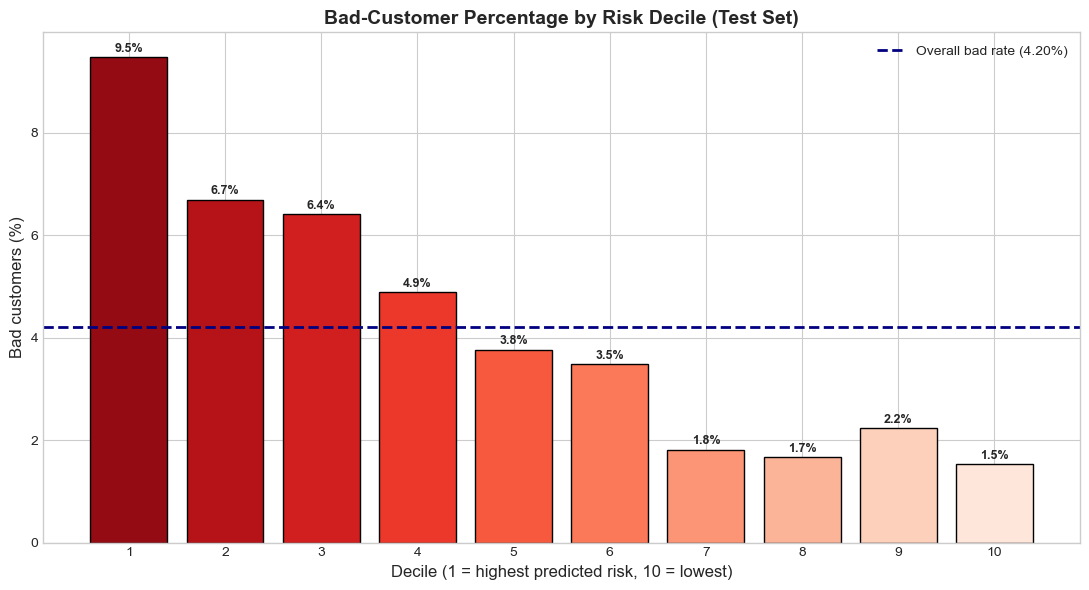

In [39]:
is_decreasing = decile_table['bad_customer_percentage'].is_monotonic_decreasing
print(f"Bad-customer percentage falls steadily from decile 1 to decile 10: {is_decreasing}")

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(decile_table['decile'], decile_table['bad_customer_percentage'],
              color=sns.color_palette('Reds_r', 10), edgecolor='black')
ax.axhline(100 * overall_bad_rate, color='navy', linestyle='--', linewidth=2,
           label=f'Overall bad rate ({100 * overall_bad_rate:.2f}%)')
for bar, val in zip(bars, decile_table['bad_customer_percentage']):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.1, f'{val:.1f}%',
            ha='center', fontsize=9, fontweight='bold')
ax.set_title('Bad-Customer Percentage by Risk Decile (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Decile (1 = highest predicted risk, 10 = lowest)', fontsize=12)
ax.set_ylabel('Bad customers (%)', fontsize=12)
ax.set_xticks(range(1, 11))
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### 📝 Reading the decile chart

- **Good sign:** the bars go down from left (decile 1) to right (decile 10). The top deciles hold a higher share of bad customers than the bottom deciles.
- **Lift in the top decile** tells the bank how much more likely a top-ranked customer is to be bad, compared with an average customer.
- **Cumulative capture** shows how many bad customers the bank would reach by reviewing the top few deciles. This is useful for deciding how many customers the collections team can realistically contact.
- **Benchmark comparison:** The business case rank-ordering benchmark is not included in the data we received, so we cannot compare decile results with it directly. If it becomes available, add it to this table for comparison.

**Business use:** Decile 1 customers can be offered early payment support or closer monitoring. Decile 10 customers may need less attention and can be treated as lower-risk.

---
# 📌 Section 14: Final Model Interpretation

**Goal:** Understand which features the final model relies on, and what this means for the bank.

**Important reminder:** Feature importance shows which inputs the model *used* to make predictions. It does **not** prove that a feature *causes* default. For example, if a high ratio of balance to limit is important, we can say the model found it useful for predicting risk. We cannot say that high utilisation causes customers to default.

**SHAP (optional):** SHAP is a method that explains how much each feature pushed a single prediction up or down. It is shown below if the `shap` library is installed and the final model is a tree model.

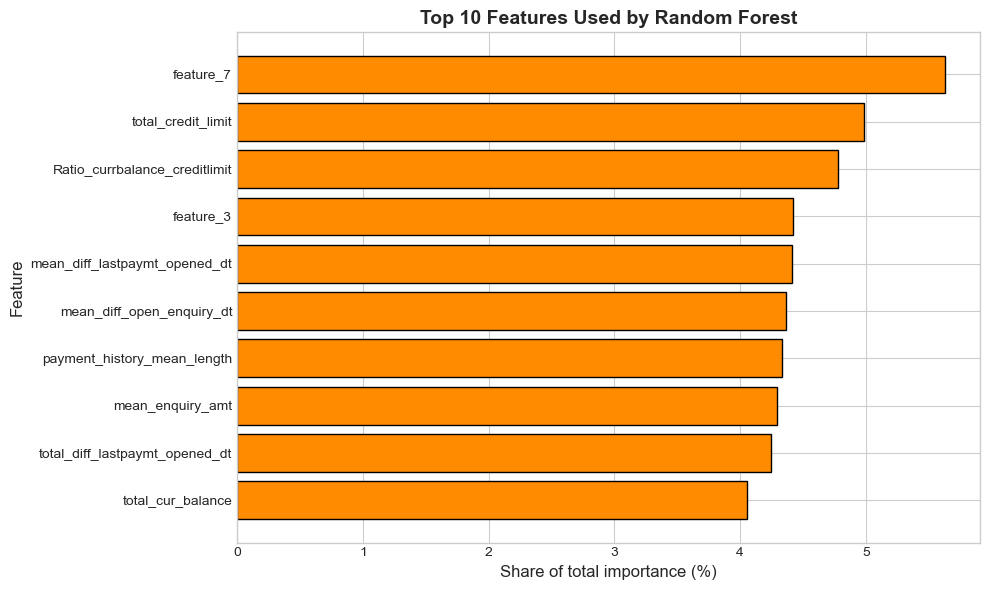

Top 10 features for the final model:
                       feature  share_%
                     feature_7   5.6257
            total_credit_limit   4.9807
 Ratio_currbalance_creditlimit   4.7804
                     feature_3   4.4161
 mean_diff_lastpaymt_opened_dt   4.4118
     mean_diff_open_enquiry_dt   4.3651
   payment_history_mean_length   4.3311
              mean_enquiry_amt   4.2928
total_diff_lastpaymt_opened_dt   4.2464
             total_cur_balance   4.0566


In [40]:
# Gain-based importance for the final model (tree models only)
final_estimator = final_model.named_steps['model']
if hasattr(final_estimator, 'booster_'):
    final_gain = final_estimator.booster_.feature_importance(importance_type='gain')
elif hasattr(final_estimator, 'feature_importances_'):
    final_gain = final_estimator.feature_importances_
else:
    final_gain = None

if final_gain is not None:
    final_importance = pd.DataFrame({'feature': SELECTED_FEATURES, 'importance': final_gain})
    final_importance['share_%'] = 100 * final_importance['importance'] / final_importance['importance'].sum()
    final_importance = final_importance.sort_values('importance', ascending=False).reset_index(drop=True)

    top10 = final_importance.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top10['feature'], top10['share_%'], color='darkorange', edgecolor='black')
    ax.set_title(f'Top 10 Features Used by {final_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Share of total importance (%)', fontsize=12)
    ax.set_ylabel('Feature', fontsize=12)
    plt.tight_layout()
    plt.show()

    print("Top 10 features for the final model:")
    print(final_importance.head(10)[['feature', 'share_%']].to_string(index=False))
else:
    print(f"{final_name} does not provide tree-based importance. See the coefficients below.")
    coefs = final_estimator.coef_[0]
    coef_table = pd.DataFrame({'feature': SELECTED_FEATURES, 'coefficient': coefs})
    coef_table = coef_table.reindex(coef_table['coefficient'].abs().sort_values(ascending=False).index)
    print(coef_table.head(10).to_string(index=False))
    print("\nA positive coefficient means higher values push the prediction towards 'bad'.")

In [41]:
# SHAP explains individual predictions. It is optional and skipped if not available.
try:
    import shap
    if 'scaler' in final_model.named_steps or not hasattr(final_estimator, 'booster_'):
        print("SHAP is shown only for the tree-based final model. Skipping for this model.")
    else:
        # Use a sample of test customers to keep computation fast
        sample_size = min(1000, len(X_test_sel))
        X_sample = final_model.named_steps['imputer'].transform(
            X_test_sel.sample(sample_size, random_state=42))
        explainer = shap.TreeExplainer(final_estimator)
        shap_values = explainer.shap_values(X_sample)
        # Depending on the SHAP version, binary models return a list or a 3D array
        if isinstance(shap_values, list):
            sv = shap_values[1]
        elif np.ndim(shap_values) == 3:
            sv = shap_values[:, :, 1]
        else:
            sv = shap_values
        shap.summary_plot(sv, X_sample, feature_names=SELECTED_FEATURES, max_display=15, show=True)
except ImportError:
    print("The 'shap' library is not installed, so SHAP plots are skipped.")
    print("To enable them, run: pip install shap")
except Exception as err:
    print(f"SHAP plot skipped due to an error: {err}")

SHAP is shown only for the tree-based final model. Skipping for this model.


### 📝 Interpretation and limitations

**Which features matter?** Use the top-10 table and chart above. Features from the payment-history, enquiry, and balance-to-limit groups are the ones to discuss with the business, because they are the ones that link most directly to credit behaviour.

**Why the model performs as it does:** Use the test-set results from Section 12. Credit default is driven by many factors that the bank may not capture in this data, so no model can be perfect. The key question is whether the model ranks customers better than chance, and whether the top deciles contain a clearly higher share of bad customers.

**Limitations:**
- Most demographic features are anonymised, so we cannot explain their real-world meaning.
- Some business-case features could not be built from the data provided (see Section 7).
- The data is a single snapshot, so we cannot test how the model would perform over time.
- The benchmark may have come from a different population or method.
- The probability cut-off of 0.5 is a default, not a value chosen for the bank's business costs.

**How the bank could use the predictions:**
- Rank customers by predicted risk and focus early-warning actions on the top deciles.
- Use the probability score as one input to credit-limit or new-application decisions, alongside other checks and human review.
- Monitor the model regularly and retrain it when customer behaviour changes.

---
# 📌 Section 15: Final Business Conclusion

The summary below is printed from this notebook's run, so the numbers always match the results above.

In [42]:
print("=" * 72)
print("PROJECT SUMMARY - BANK GOODCREDIT CREDIT RISK PREDICTION (PR-0015)")
print("=" * 72)

print("\n1. BUSINESS PROBLEM")
print("   Predict which credit card customers are likely to fall into the 30 DPD+ bucket (Bad_label = 1).")

print("\n2. DATA USED")
print(f"   Customers in demographics:   {df_demographics['customer_no'].nunique():,}")
print(f"   Account rows (before cut):   {df_account.shape[0]:,}")
print(f"   Enquiry rows (before cut):   {df_enquiry.shape[0]:,}")
print(f"   Reference (observation) date: {REF_DATE.date()}")

print("\n3. DATA CLEANING")
print("   Dates converted, text numbers converted, duplicates checked, high-missing features flagged.")

print("\n4. ENGINEERED FEATURES")
print(f"   Built: {len(ENGINEERED_FEATURES)} features from the business case (plus demographic features).")
print(f"   Skipped (not computable from the data): {', '.join(skipped_features.keys())}")
print(f"   Features kept after selection: {len(SELECTED_FEATURES)}")

print("\n5. BEST MODEL")
print(f"   Chosen by training cross-validation: {final_name}")
print(f"   Test ROC-AUC: {final_row['ROC-AUC']:.4f}")
print(f"   Test Recall (bad customers caught): {final_row['Recall (bad)']:.4f}")
print(f"   Test Precision (bad): {final_row['Precision (bad)']:.4f}")

print("\n6. GINI AND BENCHMARK")
print(f"   Test Gini: {final_gini:.2f}   |   Benchmark Gini: {BENCHMARK_GINI:.2f}   |   Difference: {gap:+.2f}")

print("\n7. RANK ORDERING")
top_bad_pct = decile_table.loc[decile_table['decile'] == 1, 'bad_customer_percentage'].iloc[0]
bottom_bad_pct = decile_table.loc[decile_table['decile'] == 10, 'bad_customer_percentage'].iloc[0]
print(f"   Decile 1 bad rate: {top_bad_pct:.2f}%   |   Decile 10 bad rate: {bottom_bad_pct:.2f}%")
print(f"   Bad rate falls steadily across deciles: {is_decreasing}")
print(f"   Bad customers reached by reviewing deciles 1-3: "
      f"{decile_table.loc[decile_table['decile'] <= 3, 'cumulative_bad_capture_%'].iloc[-1]:.1f}%")

PROJECT SUMMARY - BANK GOODCREDIT CREDIT RISK PREDICTION (PR-0015)

1. BUSINESS PROBLEM
   Predict which credit card customers are likely to fall into the 30 DPD+ bucket (Bad_label = 1).

2. DATA USED
   Customers in demographics:   23,896
   Account rows (before cut):   183,928
   Enquiry rows (before cut):   399,252
   Reference (observation) date: 2015-12-20

3. DATA CLEANING
   Dates converted, text numbers converted, duplicates checked, high-missing features flagged.

4. ENGINEERED FEATURES
   Built: 9 features from the business case (plus demographic features).
   Skipped (not computable from the data): min_months_last_30_plus, utilisation_trend, perc_unsecured_others
   Features kept after selection: 40

5. BEST MODEL
   Chosen by training cross-validation: Random Forest
   Test ROC-AUC: 0.6717
   Test Recall (bad customers caught): 0.0266
   Test Precision (bad): 0.1081

6. GINI AND BENCHMARK
   Test Gini: 34.34   |   Benchmark Gini: 37.90   |   Difference: -3.56

7. RANK ORDER

### Conclusions for a non-technical manager

**Problem solved:** We built a model that ranks credit card customers by how likely they are to fall 30 or more days behind on payments. The bank can use this ranking to focus early attention where it is needed most.

**What the data told us:**
- Bad-credit customers are rare, so the model was built to handle this imbalance and was judged on how well it catches them, not on overall accuracy.
- Payment history, recent credit enquiries, and how much of the credit limit is used are among the most useful signals.
- The top-ranked deciles contain a higher share of bad customers than the bottom deciles, which is what makes the ranking useful.

**Recommendations:**
1. Use the decile ranking to prioritise early payment support and monitoring for the highest-risk customers.
2. Treat the model as one input to credit decisions, not as an automatic approval or rejection rule.
3. Review the probability cut-off with the business, because the right trade-off between missed risky customers and wrongly flagged good customers depends on costs the bank knows best.
4. Confirm the business-case feature definitions and the benchmark's population before presenting the Gini comparison as final.

**Limitations:**
- Many features are anonymised, so their real-world meaning is uncertain.
- Three business-case features could not be built from the data provided.
- The data is one snapshot in time.
- The benchmark comparison may not be like-for-like.

**Future improvements:**
- Add a time-based validation split once reliable observation dates per customer are available.
- Build the skipped features if the data or the business-case definitions become available.
- Test calibrated probabilities, so that a score of 0.10 really means a 10% chance of being bad.
- Add SHAP explanations for individual customers so that credit staff can see why a customer was flagged.
- Monitor the model's performance over time and retrain on new data.

### 📤 Export results for the webpage
The cell below saves this run's results to `results.json`. Place `index.html` in the same folder and open it through a local server (see the note in the webpage) to view the outcomes.

In [43]:
import json

def to_records(df):
    # Convert a DataFrame to plain Python records (handles NaN as null)
    return json.loads(df.to_json(orient='records'))

export_results = {
    'final_model': final_name,
    'final_test_gini': float(final_gini),
    'benchmark_gini': float(BENCHMARK_GINI),
    'gini_difference': float(gap),
    'reference_date': str(REF_DATE.date()),
    'customers': int(df_demographics['customer_no'].nunique()),
    'test_bad_rate': float(overall_bad_rate),
    'engineered_features': ENGINEERED_FEATURES,
    'skipped_features': skipped_features,
    'selected_features_count': len(SELECTED_FEATURES),
    'cv_table': to_records(cv_table),
    'test_results': to_records(results_table),
    'decile_table': to_records(decile_table),
    'top_features': to_records(importance_table.head(20)[['feature', 'mutual_info', 'gain_share_%', 'interpretation']]),
}

with open('results.json', 'w', encoding='utf-8') as f:
    json.dump(export_results, f, indent=2)

print("✅ Saved results.json for the webpage (index.html)")

✅ Saved results.json for the webpage (index.html)
